# Pipeline final de predição de parâmetros fisiológicos

## Parte 1 - importação, limpeza e pré-processamento

A base `dataset/Unificada13052026.csv` é limpa e pré-processada neste notebook. Os espectros preparados alimentam a predição de parâmetros fisiológicos da parte 4.


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.signal import savgol_filter


def localizar_raiz(inicio: Path | None = None) -> Path:
    """Permite iniciar o kernel na raiz do projeto ou em script_final."""
    inicio = (inicio or Path.cwd()).resolve()
    for candidato in (inicio, *inicio.parents):
        if (candidato / "dataset/Unificada13052026.csv").is_file():
            return candidato
    raise FileNotFoundError("Arquivo dataset/Unificada13052026.csv não encontrado.")


ROOT = localizar_raiz()
ARQUIVO_ENTRADA = ROOT / "dataset/Unificada13052026.csv"
print(f"Base de entrada: {ARQUIVO_ENTRADA}")


### 1. Limpeza dos metadados

A identificação registrada em `nomenclaura` corrige divergências em `genotipo` e `condicao`; o bloco passa a usar maiúsculas, e o erro `C202` é corrigido para `CD202`. Os valores espectrais permanecem intactos.


In [ ]:
def limpar_metadados(df: pd.DataFrame) -> pd.DataFrame:
    """Reproduz as quatro correções de dataset/limpar_metadados.py."""
    df = df.copy()
    df["bloco"] = df["bloco"].str.upper()

    tokens = df["nomenclaura"].str.split("_")
    typo_c202 = tokens.str[1] == "C202"
    tokens.loc[typo_c202] = tokens.loc[typo_c202].apply(
        lambda t: [t[0], "CD202", *t[2:]]
    )
    df.loc[typo_c202, "nomenclaura"] = tokens.loc[typo_c202].str.join("_")

    genotipo_nomenclaura = tokens.str[1]
    genotipos_validos = {"BR16", "CD202", "EMB48"}
    divergente = genotipo_nomenclaura.isin(genotipos_validos) & (
        genotipo_nomenclaura != df["genotipo"]
    )
    df.loc[divergente, "genotipo"] = genotipo_nomenclaura[divergente]

    condicoes_validas = {
        "IRRIG": "IRRIG", "NIRRIG": "NIRRIG",
        "IRR": "IRRIG", "NIRR": "NIRRIG",
    }
    condicao_nomenclaura = tokens.str[2].map(condicoes_validas)
    divergente = condicao_nomenclaura.notna() & (
        condicao_nomenclaura != df["condicao"]
    )
    df.loc[divergente, "condicao"] = condicao_nomenclaura[divergente]
    return df


In [ ]:
base_bruta = pd.read_csv(ARQUIVO_ENTRADA, sep=";", decimal=",")
base_bruta.columns = base_bruta.columns.str.strip()
base_limpa = limpar_metadados(base_bruta)

colunas_metadados = [c for c in base_limpa.columns if not c.isdigit()]
colunas_espectrais = sorted((c for c in base_limpa.columns if c.isdigit()), key=int)
correcoes = {
    coluna: int((base_bruta[coluna] != base_limpa[coluna]).sum())
    for coluna in ("bloco", "genotipo", "nomenclaura", "condicao")
}
print(f"Amostras: {len(base_limpa)} | Metadados: {len(colunas_metadados)}")
print(f"Bandas originais: {len(colunas_espectrais)} ({colunas_espectrais[0]}–{colunas_espectrais[-1]} nm)")
display(pd.DataFrame(correcoes.items(), columns=["metadado", "linhas corrigidas"]))


### 2. Pré-processamento espectral

O fluxo usa as mesmas regras do projeto: recorte de 400 a 2450 nm, limite absoluto de 10.000 para valores extremos, correção das emendas dos detectores em 1000 e 1800 nm, interpolação dos ausentes, filtro Savitzky–Golay (janela 11, polinômio 2) e SNV por amostra.


In [ ]:
LIMITE_INF, LIMITE_SUP = 400, 2450
SPLICE_POINTS = (1000, 1800)
REFERENCE_SEQ = 1
CLIP_ABS = 1e4
WINDOW_LENGTH, POLYORDER, MODE = 11, 2, "interp"


def jump_correct(series: pd.Series) -> pd.Series:
    """Alinha os três detectores por deslocamento nas emendas."""
    series = series.sort_index()

    def get_seq(wl: float) -> int:
        for i, splice in enumerate(SPLICE_POINTS):
            if wl <= splice:
                return i
        return len(SPLICE_POINTS)

    groups = series.groupby(get_seq)

    def shift(ref: pd.Series, mov: pd.Series, right: bool = True) -> pd.Series:
        diff = (ref.iloc[-1] - mov.iloc[0]) if right else (ref.iloc[0] - mov.iloc[-1])
        return mov + diff

    for i in range(REFERENCE_SEQ, groups.ngroups - 1):
        series.update(shift(groups.get_group(i), groups.get_group(i + 1)))
    for i in range(REFERENCE_SEQ, 0, -1):
        series.update(shift(groups.get_group(i), groups.get_group(i - 1), right=False))
    return series


def limpar_valores_espurios(espectro: np.ndarray) -> np.ndarray:
    espectro = np.clip(espectro.copy(), -CLIP_ABS, CLIP_ABS)
    espectro[~np.isfinite(espectro)] = np.nan
    return espectro


def interpolar(espectro: np.ndarray) -> np.ndarray:
    espectro = espectro.copy()
    for i in range(espectro.shape[0]):
        linha = espectro[i]
        if np.isnan(linha).any():
            espectro[i] = pd.Series(linha).interpolate(limit_direction="both").to_numpy()
    return np.nan_to_num(espectro, nan=0.0, posinf=0.0, neginf=0.0)


def preprocessar(df: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray]:
    """Recorta, limpa, corrige as emendas e interpola os espectros."""
    meta = [c for c in df.columns if not c.isdigit()]
    bandas = sorted(int(c) for c in df.columns if c.isdigit())
    bandas_validas = [b for b in bandas if LIMITE_INF <= b <= LIMITE_SUP]
    if not bandas_validas:
        raise ValueError("Nenhuma banda entre 400 e 2450 nm foi encontrada.")
    w = np.array(bandas_validas, dtype=float)

    espectro = df[[str(b) for b in bandas_validas]].to_numpy(dtype=float)
    espectro_limpo = limpar_valores_espurios(espectro)
    espectro_corrigido = np.zeros_like(espectro_limpo)
    for i in range(espectro_limpo.shape[0]):
        serie = pd.Series(espectro_limpo[i], index=w, dtype="float64")
        espectro_corrigido[i] = jump_correct(serie).to_numpy()

    df_espectro = pd.DataFrame(
        interpolar(espectro_corrigido),
        columns=[str(b) for b in bandas_validas], index=df.index,
    )
    return pd.concat([df[meta], df_espectro], axis=1), w


def savitzky_golay(espectro: np.ndarray) -> np.ndarray:
    """Suaviza cada amostra com Savitzky–Golay."""
    window = WINDOW_LENGTH + (WINDOW_LENGTH % 2 == 0)
    min_window = POLYORDER + 2 if (POLYORDER + 2) % 2 else POLYORDER + 3
    window = max(window, min_window)
    suavizado = np.zeros_like(espectro)
    for i, linha in enumerate(espectro):
        suavizado[i] = (
            savgol_filter(linha, window, POLYORDER, mode=MODE)
            if len(linha) >= window else linha
        )
    return suavizado


def snv(espectro: np.ndarray) -> np.ndarray:
    """Centraliza e escala cada espectro por seu desvio padrão."""
    normalizado = np.zeros_like(espectro)
    for i, linha in enumerate(espectro):
        media, desvio = np.nanmean(linha), np.nanstd(linha)
        normalizado[i] = (
            (linha - media) / desvio
            if desvio > 0 and np.isfinite(desvio) else linha - media
        )
    return normalizado


In [ ]:
base_recortada, comprimentos_onda = preprocessar(base_limpa)
bandas_processadas = [str(int(w)) for w in comprimentos_onda]

base_suavizada = base_recortada.copy()
base_suavizada[bandas_processadas] = savitzky_golay(
    base_recortada[bandas_processadas].to_numpy(dtype=float)
)

base_normalizada = base_suavizada.copy()
base_normalizada[bandas_processadas] = snv(
    base_suavizada[bandas_processadas].to_numpy(dtype=float)
)

print(f"Pré-processamento concluído: {len(base_normalizada)} amostras, "
      f"{len(bandas_processadas)} bandas ({int(comprimentos_onda[0])}–{int(comprimentos_onda[-1])} nm).")


In [ ]:
resumo_preprocessamento = pd.DataFrame([
    {
        "estágio": nome,
        "amostras": len(base),
        "bandas": len(bandas_processadas),
        "ausentes": int(base[bandas_processadas].isna().sum().sum()),
    }
    for nome, base in (
        ("corrigido e recortado", base_recortada),
        ("suavizado", base_suavizada),
        ("normalizado (SNV)", base_normalizada),
    )
])
display(resumo_preprocessamento)


## Parte 4 — predição diária de parâmetros fisiológicos com Top 5 VIP por data

Os alvos são **clorofila total (CHL total), clorofila A, clorofila B, condutância estomática (gs), conteúdo relativo de água (CRA), taxa de transporte de elétrons (ETR) e E**. A fonte fisiológica é `ParametrosFisiologicos.xlsx`. Em cada combinação genótipo × condição, as quatro linhas da planilha correspondem aos blocos B1–B4. Os espectros matinais são reduzidos à média por parcela e pareados por **bloco × genótipo × condição × data**. Uma observação fisiológica ausente é excluída apenas do alvo e da data afetados.

| Parâmetro | Datas fisiológicas |
|---|---|
| CHL total, clorofila A, clorofila B, gs, E | 23–27/02, 02/03 e 03/03 |
| CRA | 24/02, 02/03 e 03/03 |
| ETR | 23/02, 02/03 e 03/03 |

**A mesma metodologia é aplicada a cada parâmetro e a cada data separadamente.** Os espectros corrigidos (400–2450 nm) passam por Savitzky–Golay e SNV. Bandas vizinhas correlacionadas por Spearman (`|ρ| > 0,80`, ligação completa, extensão menor que 10 nm) formam grupos; a mais associada ao alvo representa cada grupo. Um PLSR inicial, com até cinco componentes escolhidos pelo menor RMSE em validação por bloco, calcula o VIP dessas representantes. As **cinco bandas de maior VIP daquele dia** entram em um novo PLSR para a mesma data; seus componentes também são escolhidos por RMSE em validação por bloco. Cada seção mostra as bandas e as métricas de predição da data.

As predições são feitas deixando um bloco de fora. **As métricas de validação são diagnósticas:** o agrupamento, a seleção por VIP e a escolha de componentes usam a data inteira antes das dobras. Assim, os valores podem ser otimistas e não equivalem a uma validação externa aninhada. Ao final, um gráfico por parâmetro reúne todas as datas e as cinco bandas VIP encontradas em cada uma.

### 4.1. Planilha fisiológica e pareamento

A célula seguinte lê `ParametrosFisiologicos.xlsx`, normaliza os nomes das colunas, mapeia as quatro repetições de cada genótipo × condição para B1–B4 e calcula a média das leituras matinais de cada parcela em cada dia. O pareamento exige uma linha espectral por parcela; uma medida fisiológica ausente é excluída somente daquele alvo e daquela data.


In [ ]:
from scipy.stats import rankdata, spearmanr
import matplotlib.pyplot as plt
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

MAPA_FISIOLOGICO = {
    "23/02": "D02M", "24/02": "D03M", "25/02": "D04M",
    "26/02": "D05M", "27/02": "D06M", "02/03": "D09M", "03/03": "D10M",
}
DATAS_ETR = ("23/02", "02/03", "03/03")
DATAS_CRA = ("24/02", "02/03", "03/03")
ALVOS_FISIOLOGICOS = {
    "CHL total": ("CHL TOTAL", tuple(MAPA_FISIOLOGICO)),
    "Clorofila A": ("CHL A", tuple(MAPA_FISIOLOGICO)),
    "Clorofila B": ("CHL B", tuple(MAPA_FISIOLOGICO)),
    "gs": ("gs", tuple(MAPA_FISIOLOGICO)),
    "CRA": ("CRA", DATAS_CRA),
    "ETR": ("ETR", DATAS_ETR),
    "E": ("E", tuple(MAPA_FISIOLOGICO)),
}
PASTA_FISIOLOGIA = ROOT / "script_final/outputs/fisiologia_vip_por_dia"
PASTA_FISIOLOGIA.mkdir(parents=True, exist_ok=True)

fisiologia = pd.read_excel(ROOT / "ParametrosFisiologicos.xlsx")
fisiologia.columns = [" ".join(str(c).replace(".", "/").split()) for c in fisiologia.columns]
fisiologia["genotipo"] = fisiologia["Genótipo"]
fisiologia["condicao"] = fisiologia["Condição"].replace({
    "IRR": "IRRIG", "NIR": "NIRRIG", "NIRR": "NIRRIG",
})
fisiologia["bloco"] = (
    fisiologia.groupby(["genotipo", "condicao"], sort=False).cumcount()
    .map(lambda i: f"B{i + 1}")
)
assert len(fisiologia) == 24
assert fisiologia.groupby(["genotipo", "condicao"]).size().eq(4).all()
CHAVES_FISIOLOGIA = ["bloco", "genotipo", "condicao"]

bandas_fisiologia_norm = comprimentos_onda.astype(int)
colunas_fisiologia_norm = [str(b) for b in bandas_fisiologia_norm]
def medias_espectrais_por_parcela(base: pd.DataFrame, colunas: list[str]) -> pd.DataFrame:
    usadas = ["data_coleta", *CHAVES_FISIOLOGIA, *colunas]
    manha = base.loc[base["turno"].eq("manha"), usadas].copy()
    return manha.groupby(["data_coleta", *CHAVES_FISIOLOGIA], as_index=False)[colunas].mean()


espectros_fisiologia_norm = medias_espectrais_por_parcela(
    base_normalizada, colunas_fisiologia_norm
)
def parear_fisiologia(alvo: str, data: str, espectros: pd.DataFrame) -> pd.DataFrame:
    prefixo, _ = ALVOS_FISIOLOGICOS[alvo]
    coluna = f"{prefixo} ({data})"
    if coluna not in fisiologia:
        raise KeyError(f"Coluna fisiológica ausente: {coluna}")
    medida = fisiologia[CHAVES_FISIOLOGIA].copy()
    medida["observado"] = pd.to_numeric(
        fisiologia[coluna].astype(str).str.replace(",", ".", regex=False),
        errors="coerce",
    )
    coleta = MAPA_FISIOLOGICO[data]
    espectro_dia = espectros.loc[espectros["data_coleta"].eq(coleta)].drop(
        columns="data_coleta"
    )
    dados = medida.merge(
        espectro_dia, on=CHAVES_FISIOLOGIA, how="inner", validate="one_to_one"
    )
    if len(dados) != 24:
        raise ValueError(f"{alvo} {data}: pareamento incompleto ({len(dados)}/24).")
    return dados.dropna(subset=["observado"]).reset_index(drop=True)


contagens_fisiologia = pd.DataFrame([
    {"parametro": alvo, "data": data, "coleta_espectral": MAPA_FISIOLOGICO[data],
     "pares_validos": len(parear_fisiologia(
         alvo, data, espectros_fisiologia_norm
     ))}
    for alvo, (_, datas) in ALVOS_FISIOLOGICOS.items() for data in datas
])
display(contagens_fisiologia)

### 4.2. Funções para PLSR e VIP

As funções abaixo agrupam bandas vizinhas por Spearman, escolhem componentes por validação por bloco, calculam o VIP e produzem predições deixando um bloco de fora.

In [ ]:
def grupos_spearman_fisiologia(X: np.ndarray, w: np.ndarray) -> np.ndarray:
    """Ligação completa local: |ρ| > 0,80 em grupos com extensão <10 nm."""
    postos = rankdata(X, axis=0, method="average")
    z = postos - postos.mean(axis=0)
    norma = np.sqrt((z ** 2).sum(axis=0))
    norma[norma == 0] = np.inf
    z /= norma
    grupos = np.zeros(len(w), dtype=int)
    membros = [0]
    atual = 0
    for j in range(1, len(w)):
        correlacionada = (
            w[j] - w[membros[0]] < 10
            and np.all(np.abs(z[:, membros].T @ z[:, j]) > 0.80)
        )
        if correlacionada:
            membros.append(j)
        else:
            atual += 1
            membros = [j]
        grupos[j] = atual
    return grupos


def componentes_plsr_por_bloco(
    X: np.ndarray, y: np.ndarray, blocos: np.ndarray, max_componentes: int,
) -> tuple[int, pd.DataFrame]:
    dobras = list(GroupKFold(n_splits=len(np.unique(blocos))).split(X, y, blocos))
    limite = min(max_componentes, X.shape[1], min(len(treino) - 1 for treino, _ in dobras))
    linhas = []
    for n in range(1, limite + 1):
        previsto = np.full(len(y), np.nan)
        for treino, teste in dobras:
            modelo = PLSRegression(n_components=n, scale=True).fit(X[treino], y[treino])
            previsto[teste] = modelo.predict(X[teste]).ravel()
        linhas.append({
            "componentes": n, "r2_cv_bloco": r2_score(y, previsto),
            "rmse_cv_bloco": mean_squared_error(y, previsto) ** 0.5,
        })
    tabela = pd.DataFrame(linhas)
    return int(tabela.loc[tabela["rmse_cv_bloco"].idxmin(), "componentes"]), tabela


def prever_plsr_por_bloco(X: np.ndarray, y: np.ndarray, blocos: np.ndarray, n: int) -> np.ndarray:
    previsto = np.full(len(y), np.nan)
    for treino, teste in GroupKFold(n_splits=len(np.unique(blocos))).split(X, y, blocos):
        previsto[teste] = PLSRegression(n_components=n, scale=True).fit(
            X[treino], y[treino]
        ).predict(X[teste]).ravel()
    return previsto


def correlacao_spearman_alvo(X: np.ndarray, y: np.ndarray) -> np.ndarray:
    postos_x = rankdata(X, axis=0, method="average")
    postos_y = rankdata(y, method="average")
    zx = postos_x - postos_x.mean(axis=0)
    zy = postos_y - postos_y.mean()
    norma_x = np.sqrt((zx ** 2).sum(axis=0))
    norma_x[norma_x == 0] = np.inf
    norma_y = np.sqrt((zy ** 2).sum())
    return zx.T @ zy / (norma_x * norma_y)


def vip_plsr(modelo: PLSRegression) -> np.ndarray:
    t, pesos, q = modelo.x_scores_, modelo.x_weights_, modelo.y_loadings_
    ssy = (q ** 2).ravel() * (t ** 2).sum(axis=0)
    pesos_norm = pesos / np.linalg.norm(pesos, axis=0, keepdims=True)
    return np.sqrt(pesos.shape[0] * ((pesos_norm ** 2) * ssy).sum(axis=1) / ssy.sum())


def resumir_plsr(alvo: str, data: str, coleta: str, X: np.ndarray, y: np.ndarray,
                 blocos: np.ndarray, bandas: np.ndarray, n: int,
                 representantes: int, metodo: str) -> tuple[dict, np.ndarray, PLSRegression]:
    modelo = PLSRegression(n_components=n, scale=True).fit(X, y)
    ajuste = modelo.predict(X).ravel()
    previsto = prever_plsr_por_bloco(X, y, blocos, n)
    resumo = {
        "parametro": alvo, "data": data, "coleta_espectral": coleta,
        "metodo": metodo, "n": len(y), "bandas_entrada": len(bandas),
        "representantes": representantes, "bandas_modelo": X.shape[1],
        "componentes": n, "r2_ajuste": r2_score(y, ajuste),
        "rmse_ajuste": mean_squared_error(y, ajuste) ** 0.5,
        "r2_cv_bloco": r2_score(y, previsto),
        "rmse_cv_bloco": mean_squared_error(y, previsto) ** 0.5,
        "status": "Modelo ajustado",
    }
    return resumo, previsto, modelo


### 4.3. Seleção das cinco bandas VIP e PLSR independentes por data

In [ ]:
modelos_fisiologia_diarios = {}
resumos_fisiologia, predicoes_fisiologia = [], []
bandas_vip_fisiologia = []

def executar_plsr_vip_por_dia(alvo: str) -> None:
    _, datas = ALVOS_FISIOLOGICOS[alvo]
    pasta_alvo = PASTA_FISIOLOGIA / alvo.lower().replace(" ", "_")
    pasta_alvo.mkdir(parents=True, exist_ok=True)
    for data in datas:
        dia = parear_fisiologia(alvo, data, espectros_fisiologia_norm)
        X = dia[colunas_fisiologia_norm].to_numpy(dtype=float)
        y = dia["observado"].to_numpy(dtype=float)
        blocos = dia["bloco"].to_numpy()

        # Uma representante por grupo local de bandas correlacionadas no dia.
        rho = correlacao_spearman_alvo(X, y)
        grupos = grupos_spearman_fisiologia(X, bandas_fisiologia_norm)
        representantes = np.array([
            indices[np.nanargmax(np.abs(rho[indices]))]
            for grupo in np.unique(grupos)
            if (indices := np.flatnonzero(grupos == grupo)).size
        ], dtype=int)
        if len(representantes) < 5:
            raise ValueError(f"{alvo} {data}: apenas {len(representantes)} representantes; são necessárias cinco.")
        X_representantes = X[:, representantes]
        n_inicial, componentes_iniciais = componentes_plsr_por_bloco(
            X_representantes, y, blocos, max_componentes=5
        )
        modelo_inicial = PLSRegression(n_components=n_inicial, scale=True).fit(
            X_representantes, y
        )
        vip_inicial = vip_plsr(modelo_inicial)
        ordem = np.argsort(-vip_inicial, kind="stable")[:5]
        bandas_top5 = bandas_fisiologia_norm[representantes[ordem]]
        X_top5 = X_representantes[:, ordem]

        n_final, componentes_finais = componentes_plsr_por_bloco(
            X_top5, y, blocos, max_componentes=5
        )
        resumo, previsto, modelo = resumir_plsr(
            alvo, data, MAPA_FISIOLOGICO[data], X_top5, y, blocos,
            bandas_fisiologia_norm, n_final, len(representantes),
            "Top 5 VIP por data / PLSR diário",
        )
        resumo["bandas_nm"] = ", ".join(map(str, bandas_top5))
        resumos_fisiologia.append(resumo)
        modelos_fisiologia_diarios[(alvo, data)] = modelo
        predicoes_fisiologia.append(dia[[*CHAVES_FISIOLOGIA, "observado"]].assign(
            data=data, parametro=alvo, predito_cv_bloco=previsto,
            residuo_cv_bloco=y - previsto,
        ))

        top5 = pd.DataFrame({
            "parametro": alvo, "data": data, "coleta_espectral": MAPA_FISIOLOGICO[data],
            "posicao_vip": np.arange(1, 6), "banda_nm": bandas_top5,
            "vip_selecao": vip_inicial[ordem],
            "vip_modelo_final": vip_plsr(modelo),
            "rho_spearman_alvo": rho[representantes[ordem]],
        })
        bandas_vip_fisiologia.append(top5)
        sufixo = data.replace("/", "_")
        top5.to_csv(pasta_alvo / f"top5_vip_{sufixo}.csv", sep=";", index=False)
        componentes_iniciais.to_csv(
            pasta_alvo / f"componentes_iniciais_{sufixo}.csv", sep=";", index=False
        )
        componentes_finais.to_csv(
            pasta_alvo / f"componentes_finais_{sufixo}.csv", sep=";", index=False
        )
        print(f"{alvo} {data}: top 5 VIP = {', '.join(map(str, bandas_top5))} nm")

def mostrar_resumo_fisiologico(alvo: str) -> None:
    linhas = [r for r in resumos_fisiologia if r["parametro"] == alvo]
    display(pd.DataFrame(linhas)[[
        "parametro", "data", "n", "bandas_nm", "componentes",
        "r2_cv_bloco", "rmse_cv_bloco",
    ]].round(3))

In [ ]:
CORES_PREDICAO_DIARIA = {"IRRIG": "#2374ab", "NIRRIG": "#d95f02"}

def tabela_top5_vip_diaria(alvo: str) -> pd.DataFrame:
    _, datas = ALVOS_FISIOLOGICOS[alvo]
    bandas = pd.concat(
        [tabela for tabela in bandas_vip_fisiologia
         if tabela["parametro"].iat[0] == alvo],
        ignore_index=True,
    )
    tabela = bandas.pivot(index="data", columns="posicao_vip", values="banda_nm")
    tabela = tabela.loc[list(datas)]
    tabela.index.name = "Data"
    tabela.columns = [f"VIP {posicao} (nm)" for posicao in tabela.columns]
    return tabela.reset_index()


def mostrar_bandas_e_graficos_diarios(alvo: str) -> None:
    _, datas = ALVOS_FISIOLOGICOS[alvo]
    nome = alvo.lower().replace(" ", "_")
    pasta = PASTA_FISIOLOGIA / nome
    tabela = tabela_top5_vip_diaria(alvo)
    tabela.to_csv(pasta / "tabela_top5_vip_por_dia.csv", sep=";", index=False)
    display(tabela)

    for data in datas:
        resumo = next(
            linha for linha in resumos_fisiologia
            if linha["parametro"] == alvo and linha["data"] == data
        )
        predicoes = next(
            tabela for tabela in predicoes_fisiologia
            if tabela["parametro"].iat[0] == alvo
            and tabela["data"].iat[0] == data
        )
        valores = np.r_[
            predicoes["observado"].to_numpy(),
            predicoes["predito_cv_bloco"].to_numpy(),
        ]
        margem = max(0.08 * np.ptp(valores), 0.01)
        minimo, maximo = valores.min() - margem, valores.max() + margem
        figura, eixo = plt.subplots(figsize=(6.2, 5.6), constrained_layout=True)
        for condicao, cor in CORES_PREDICAO_DIARIA.items():
            parcela = predicoes.loc[predicoes["condicao"].eq(condicao)]
            eixo.scatter(
                parcela["observado"], parcela["predito_cv_bloco"],
                color=cor, s=55, alpha=0.85, edgecolors="white",
                linewidths=0.5, label=condicao,
            )
        eixo.plot([minimo, maximo], [minimo, maximo], "--",
                  color="#555555", linewidth=1, label="1:1")
        eixo.set(
            xlim=(minimo, maximo), ylim=(minimo, maximo),
            xlabel=f"{alvo} observado",
            ylabel=f"{alvo} predito (CV por bloco)",
        )
        eixo.set_aspect("equal", adjustable="box")
        eixo.grid(alpha=0.2)
        eixo.set_title(
            f"{alvo} — {data}\n"
            f"Top 5 VIP: {resumo['bandas_nm']} nm\n"
            f"R² CV = {resumo['r2_cv_bloco']:.2f} | "
            f"RMSE CV = {resumo['rmse_cv_bloco']:.2f}"
        )
        eixo.legend(loc="best")
        arquivo = pasta / f"predicao_{nome}_{data.replace('/', '_')}.png"
        figura.savefig(arquivo, dpi=180, bbox_inches="tight")
        display(figura)
        plt.close(figura)


### 4.4. CHL total

Em 23–27/02, 02/03 e 03/03, cada data tem suas próprias cinco bandas VIP e seu próprio PLSR. A tabela abaixo mostra as bandas selecionadas e a predição por validação por bloco.

In [ ]:
executar_plsr_vip_por_dia("CHL total")
mostrar_resumo_fisiologico("CHL total")

#### Bandas VIP e gráficos de predição por data

A tabela mostra as cinco bandas de cada dia em ordem de VIP. Os gráficos usam essas bandas no PLSR da própria data e exibem as predições ao deixar um bloco de fora.


Data,VIP 1 (nm),VIP 2 (nm),VIP 3 (nm),VIP 4 (nm),VIP 5 (nm)
23/02,1937,1929,1926,1949,1911
24/02,717,711,728,704,1368
25/02,727,718,714,737,705
26/02,1371,723,710,702,718
27/02,725,713,704,715,735
02/03,725,716,713,737,1913
03/03,733,1895,1905,730,741


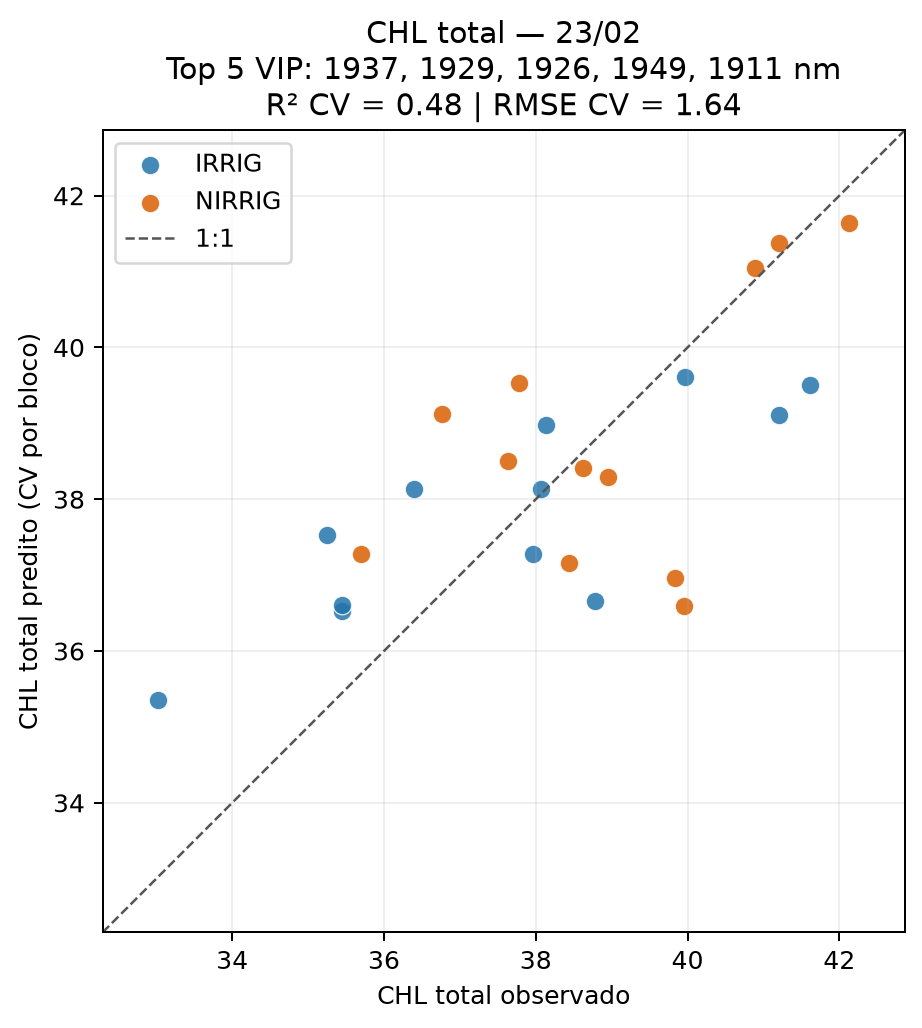

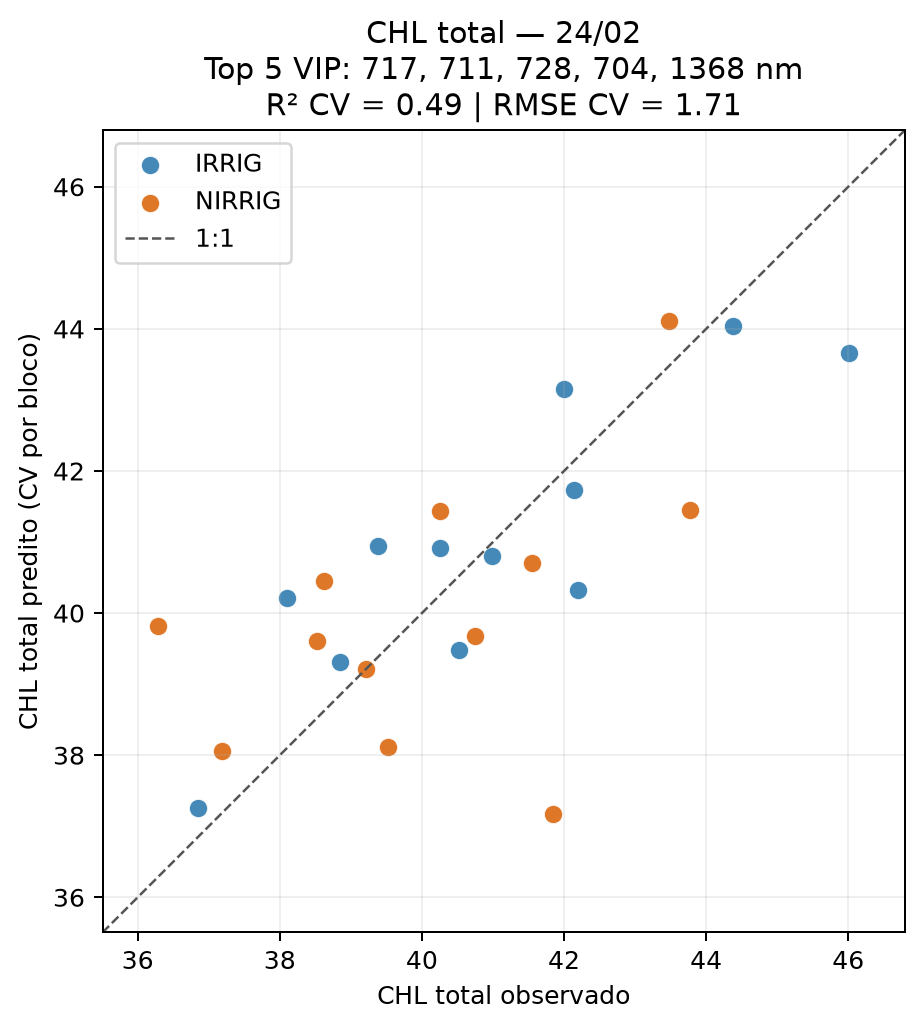

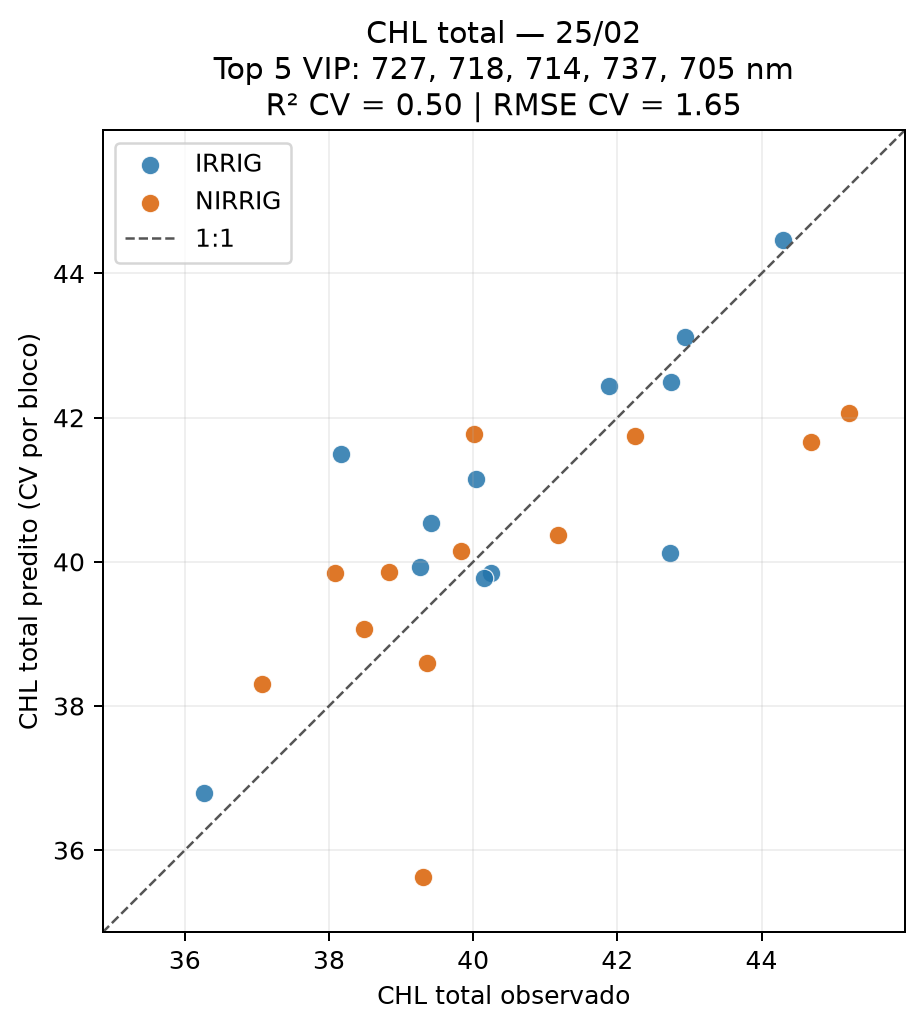

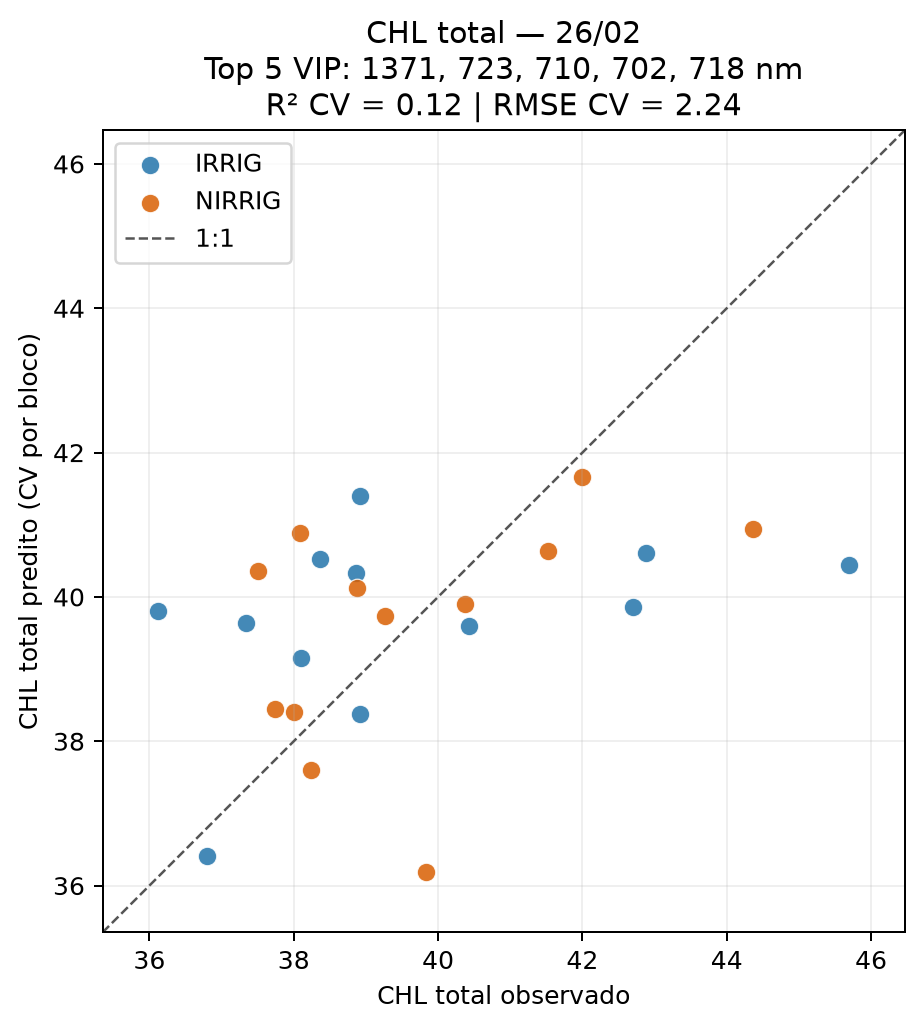

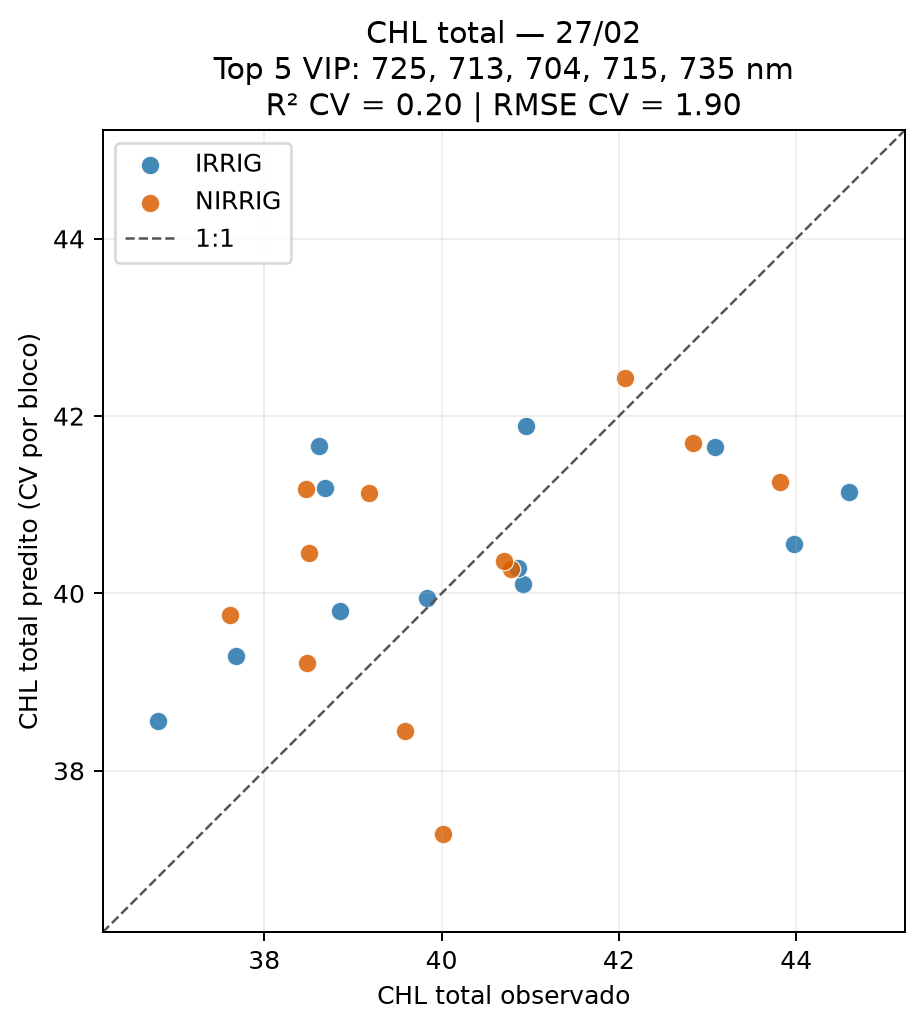

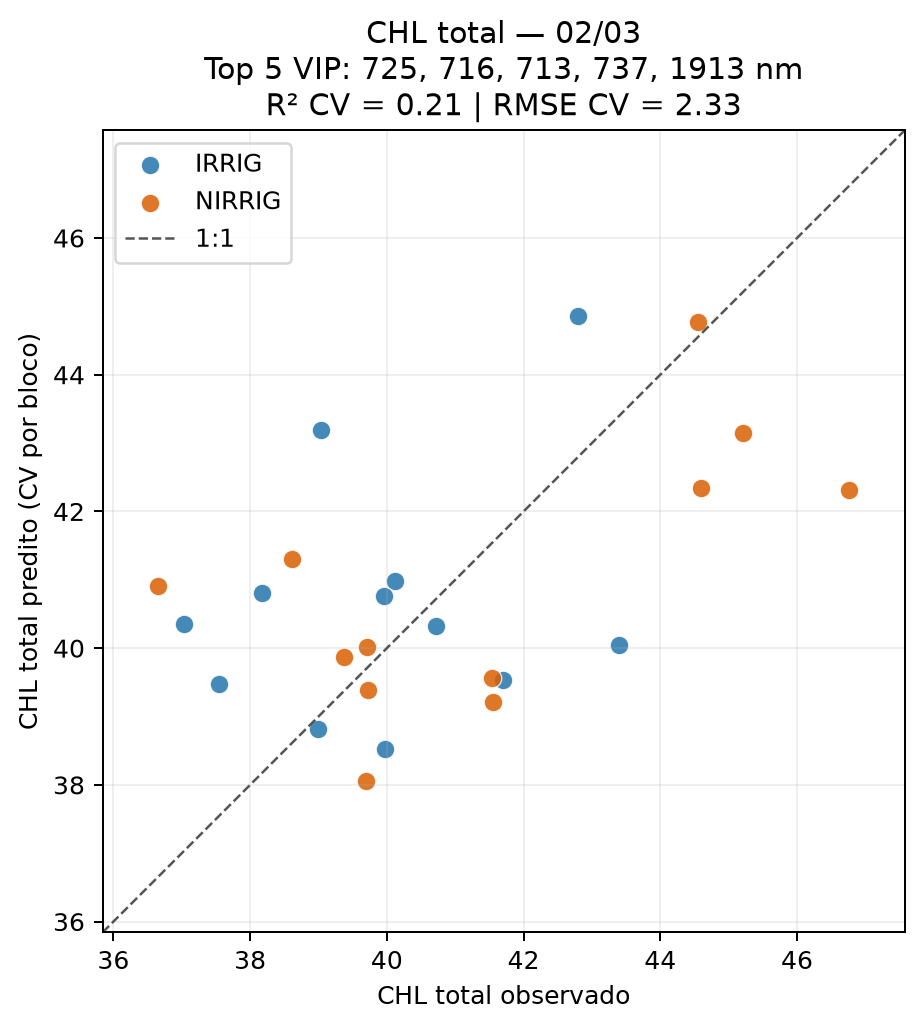

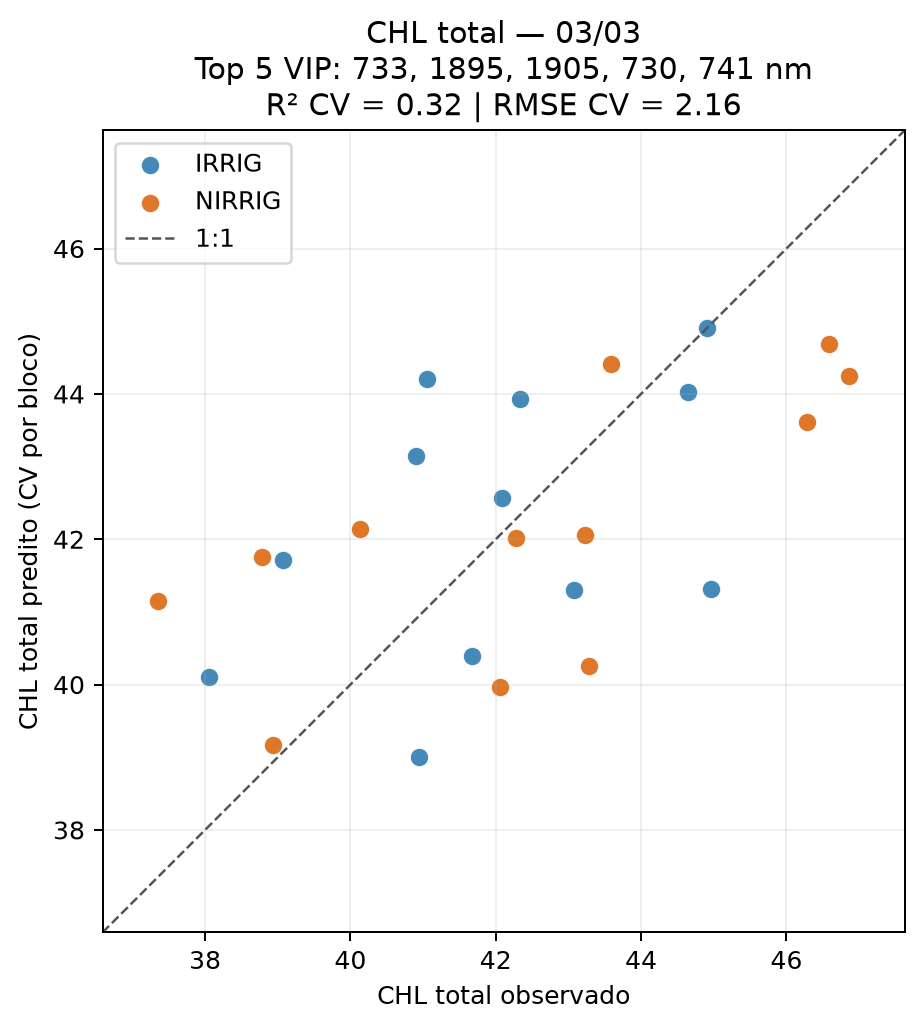

In [ ]:
mostrar_bandas_e_graficos_diarios("CHL total")


### 4.5. Clorofila A

Em 23–27/02, 02/03 e 03/03, cada data tem suas próprias cinco bandas VIP e seu próprio PLSR. A tabela abaixo mostra as bandas selecionadas e a predição por validação por bloco.

In [ ]:
executar_plsr_vip_por_dia("Clorofila A")
mostrar_resumo_fisiologico("Clorofila A")

#### Bandas VIP e gráficos de predição por data

A tabela mostra as cinco bandas de cada dia em ordem de VIP. Os gráficos usam essas bandas no PLSR da própria data e exibem as predições ao deixar um bloco de fora.


Data,VIP 1 (nm),VIP 2 (nm),VIP 3 (nm),VIP 4 (nm),VIP 5 (nm)
23/02,1943,1929,1949,1926,1957
24/02,1368,1376,717,725,714
25/02,731,737,718,716,703
26/02,1371,711,702,723,718
27/02,1352,715,713,1364,1365
02/03,725,737,716,1930,713
03/03,1895,1906,1890,1912,1961


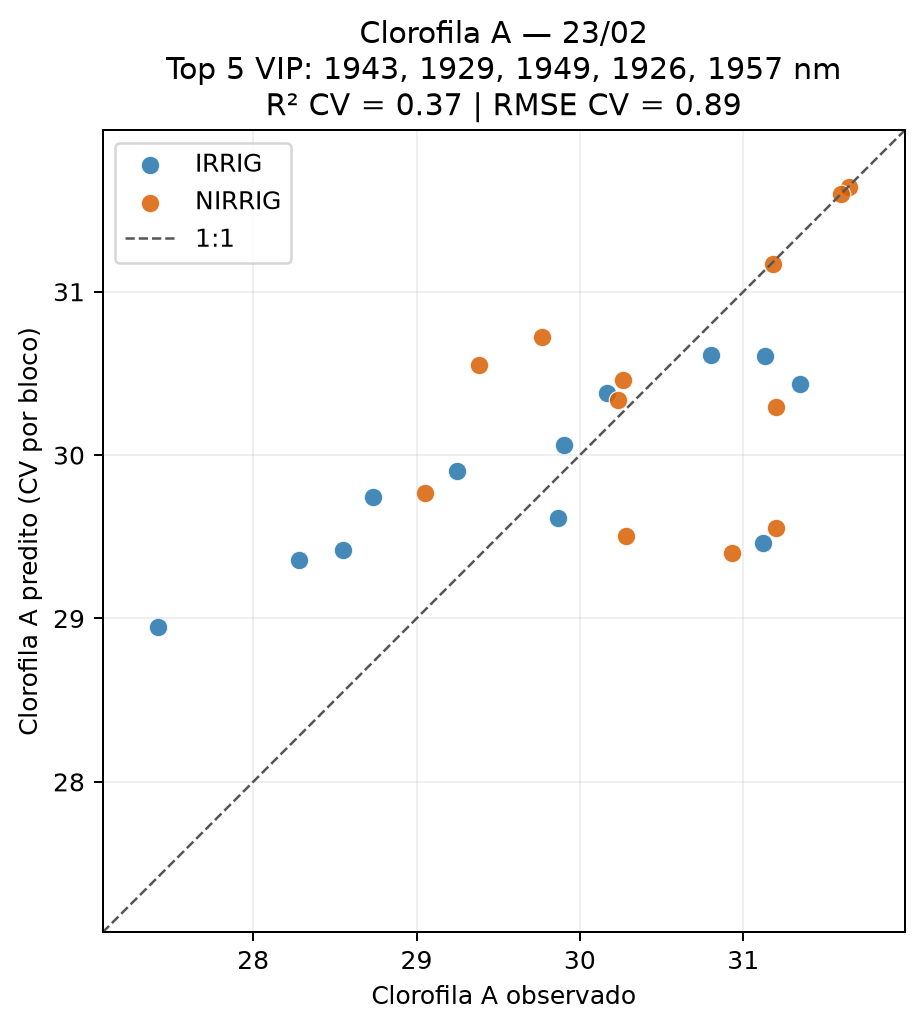

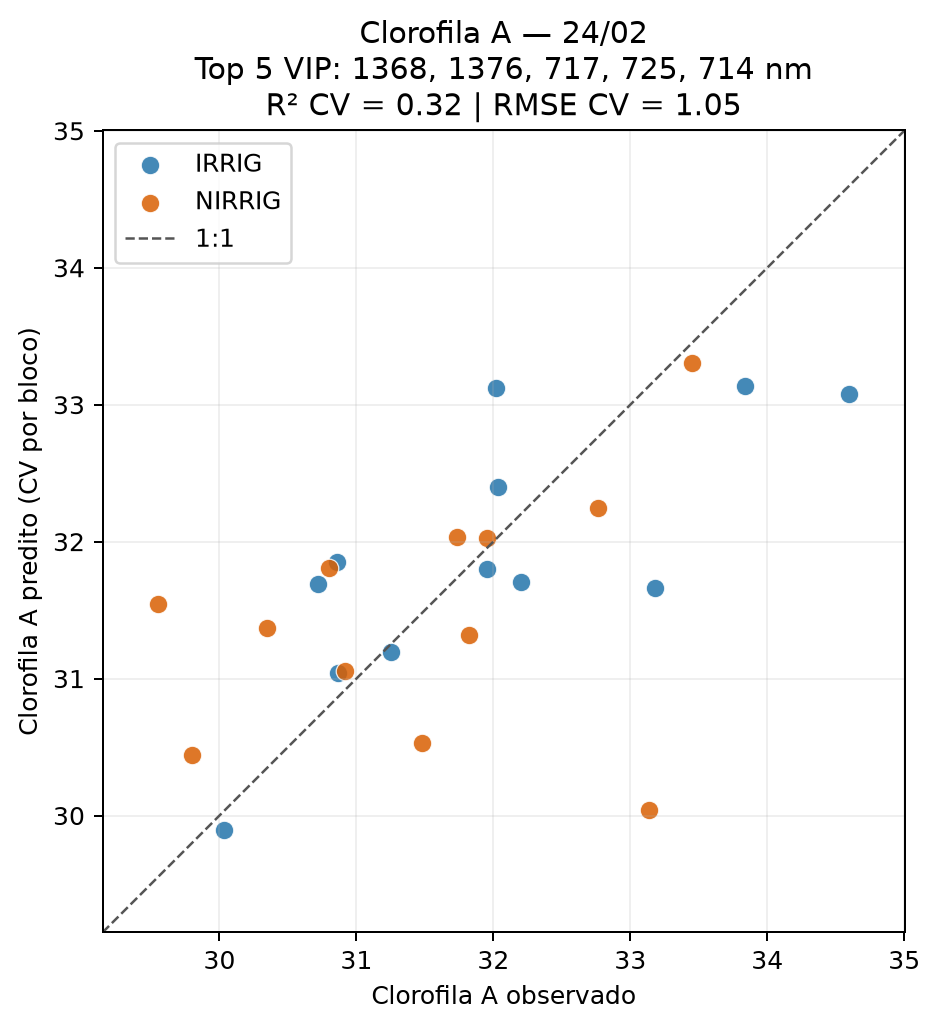

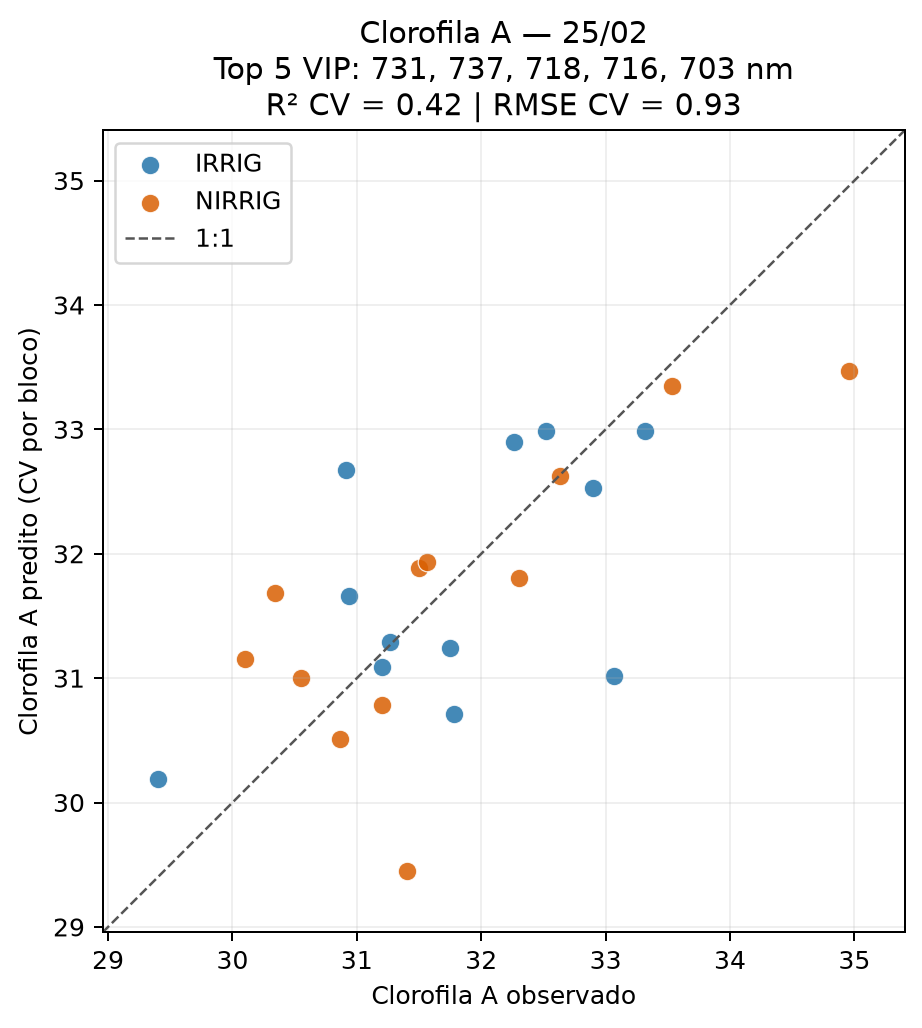

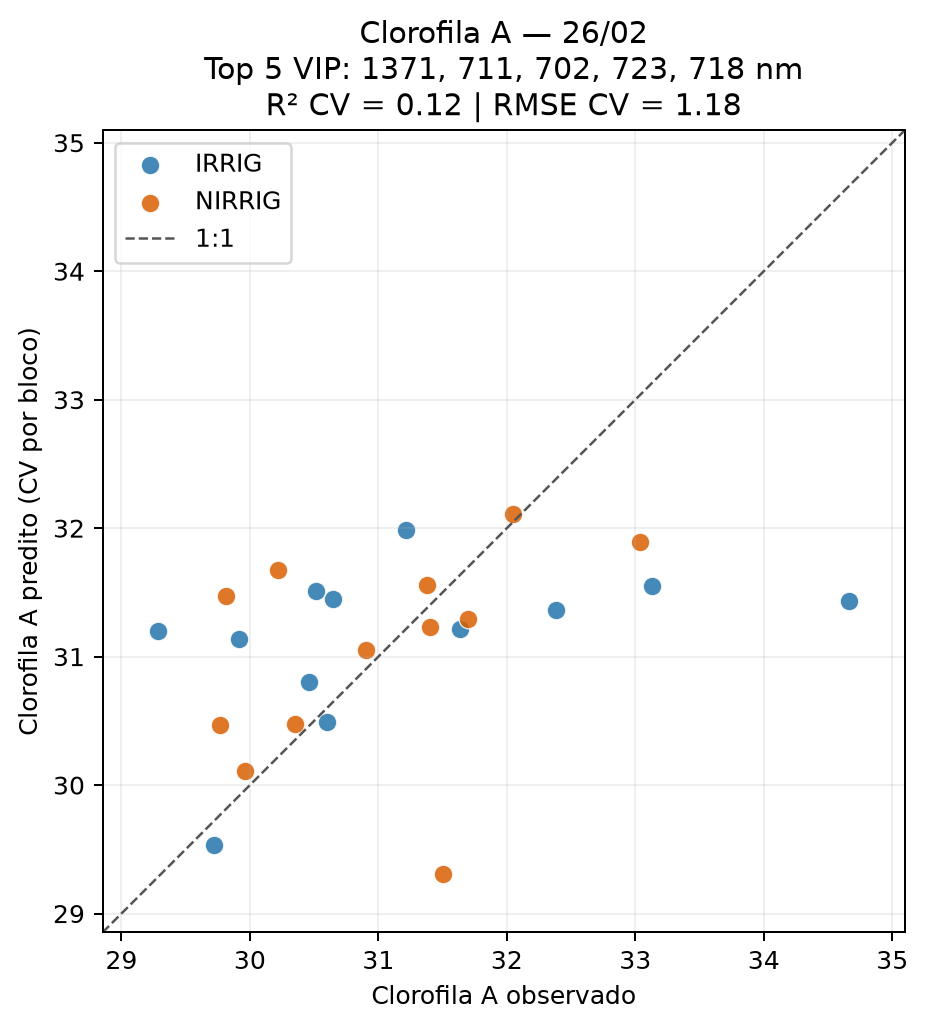

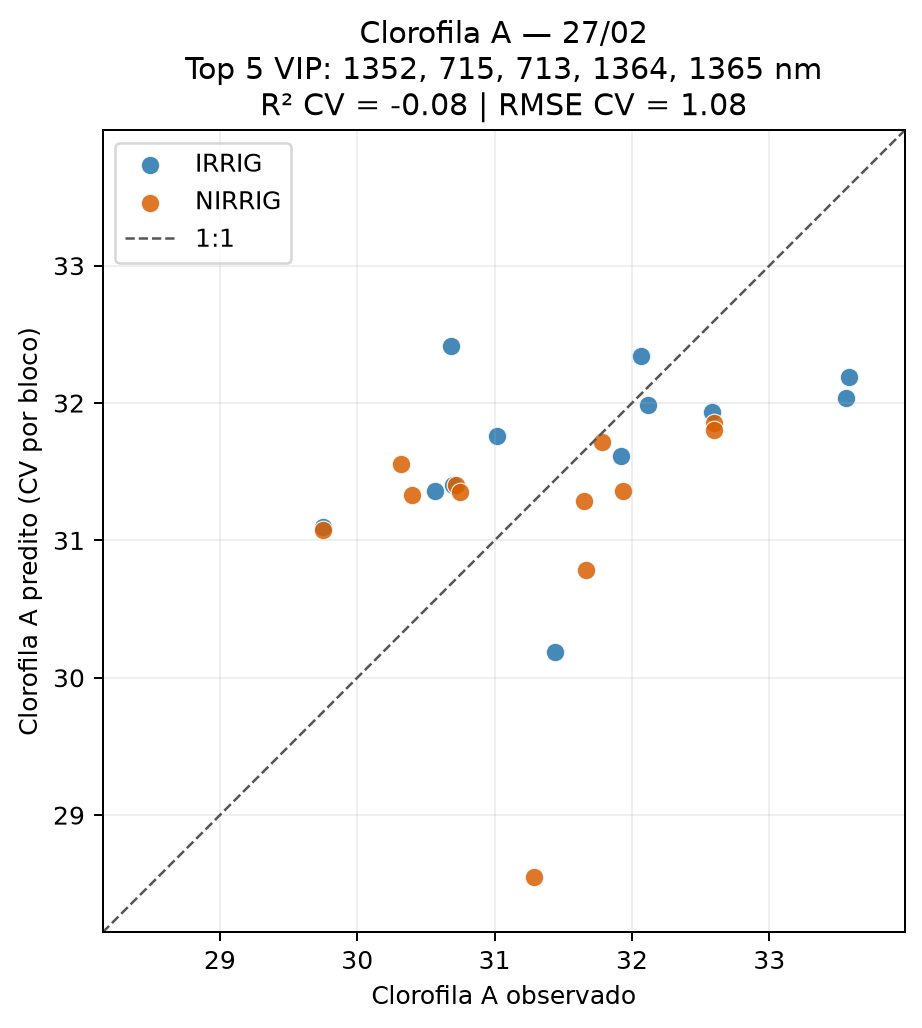

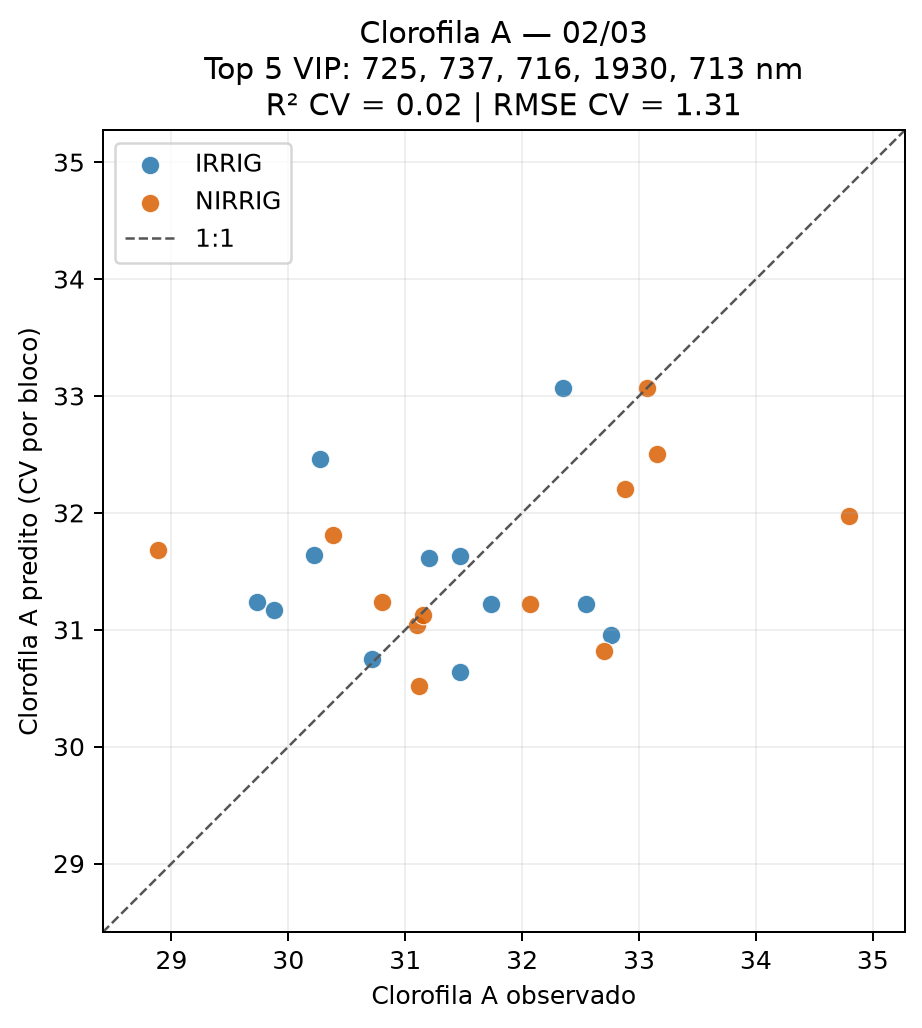

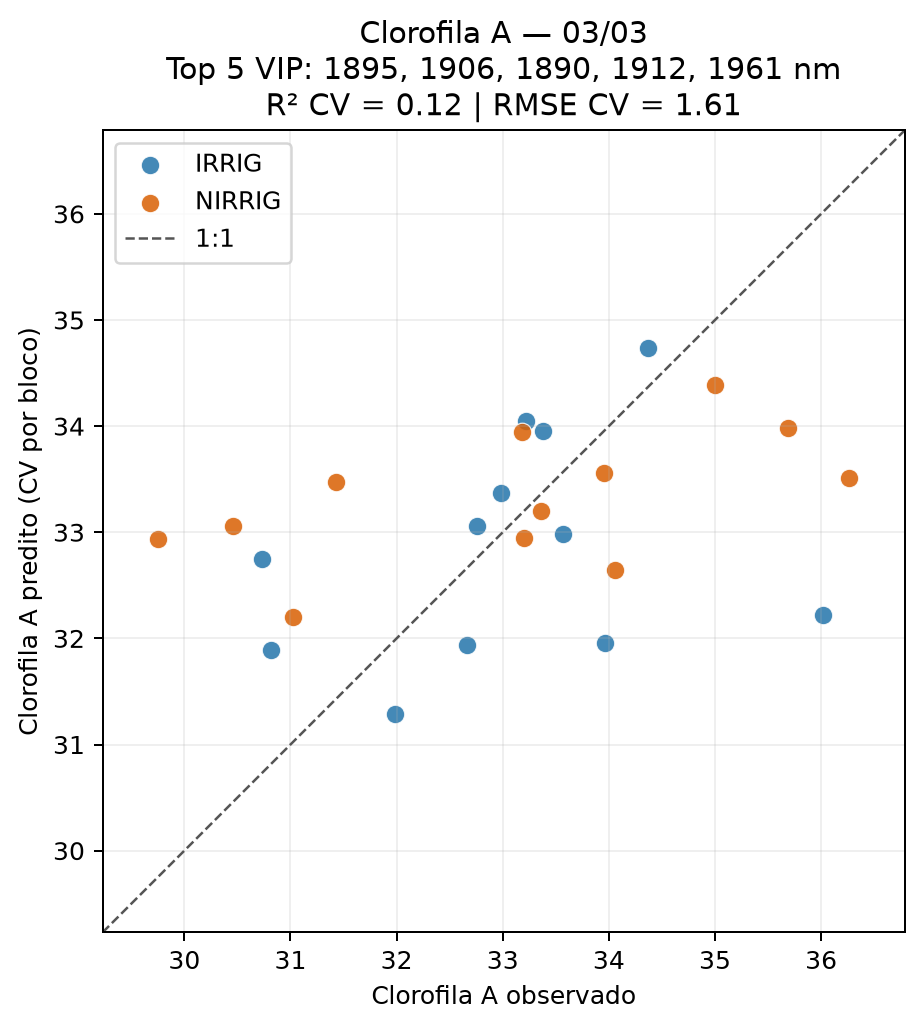

In [ ]:
mostrar_bandas_e_graficos_diarios("Clorofila A")


### 4.6. Clorofila B

Em 23–27/02, 02/03 e 03/03, cada data tem suas próprias cinco bandas VIP e seu próprio PLSR. A tabela abaixo mostra as bandas selecionadas e a predição por validação por bloco.

In [ ]:
executar_plsr_vip_por_dia("Clorofila B")
mostrar_resumo_fisiologico("Clorofila B")

#### Bandas VIP e gráficos de predição por data

A tabela mostra as cinco bandas de cada dia em ordem de VIP. Os gráficos usam essas bandas no PLSR da própria data e exibem as predições ao deixar um bloco de fora.


Data,VIP 1 (nm),VIP 2 (nm),VIP 3 (nm),VIP 4 (nm),VIP 5 (nm)
23/02,1928,1937,1924,1911,1949
24/02,717,725,711,704,550
25/02,727,723,716,706,737
26/02,732,725,1371,702,718
27/02,719,713,726,704,735
02/03,725,716,713,735,703
03/03,733,741,730,535,540


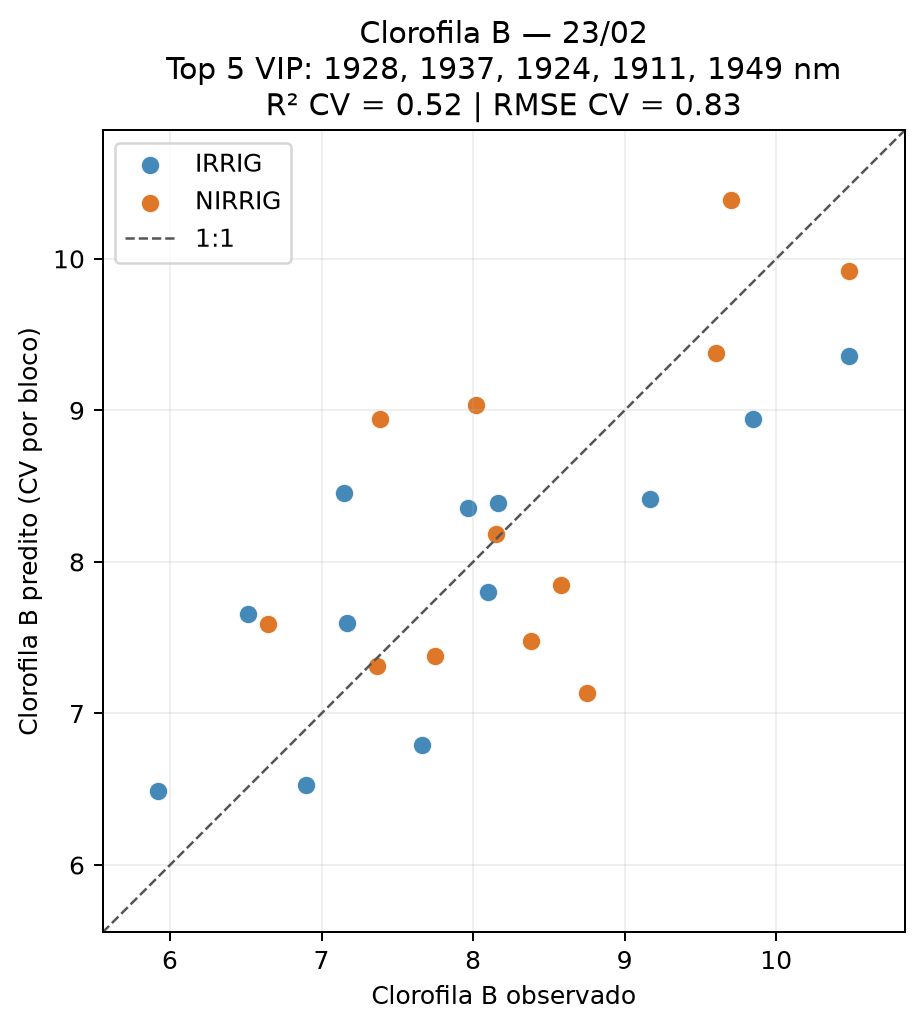

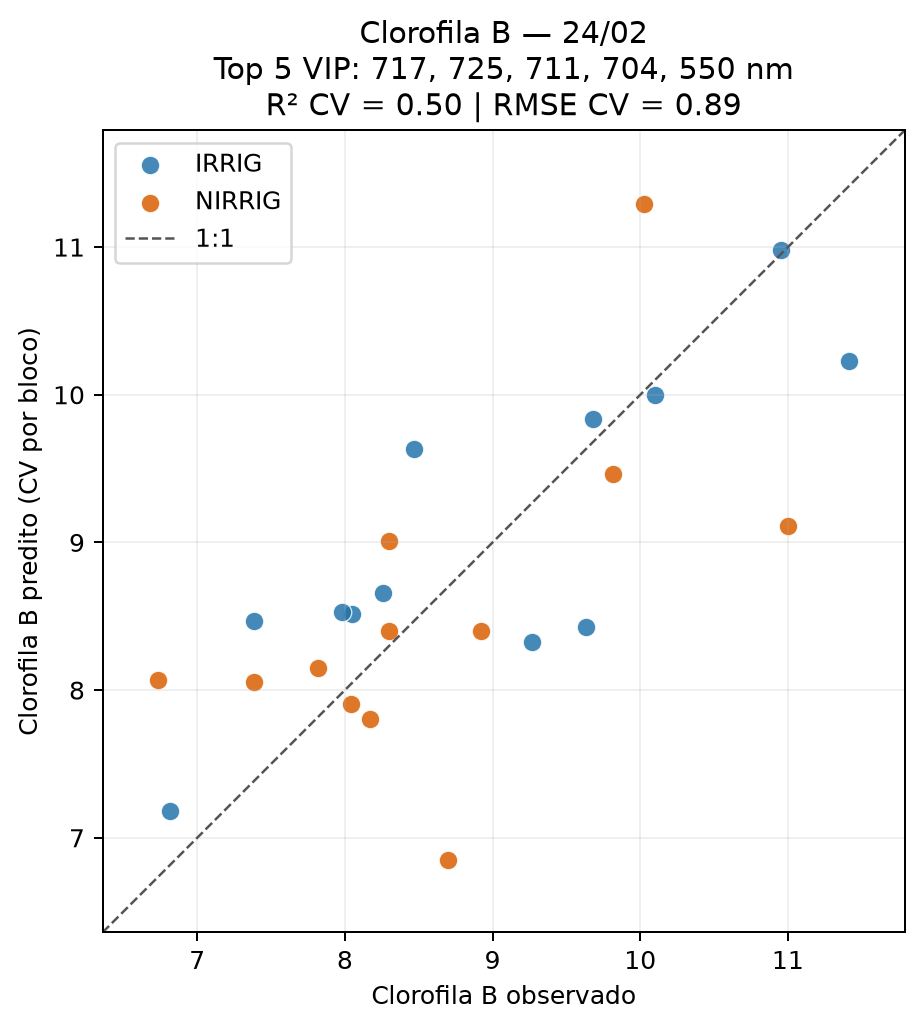

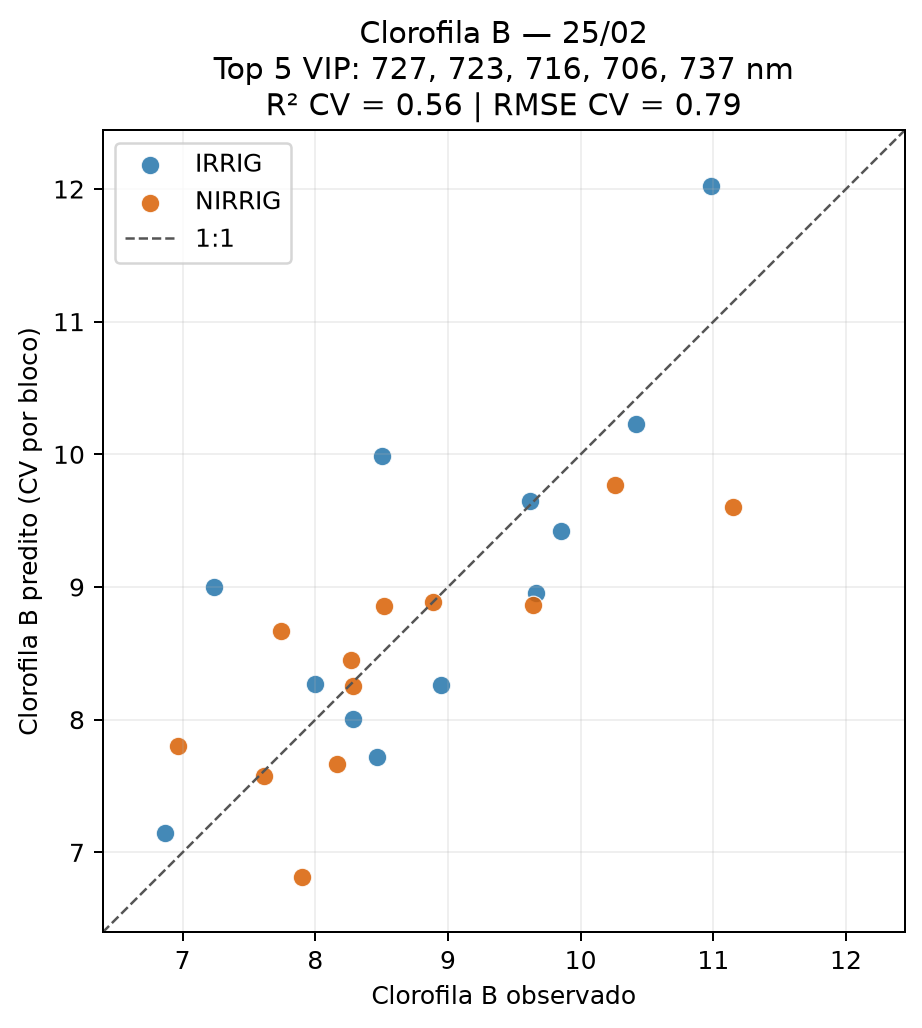

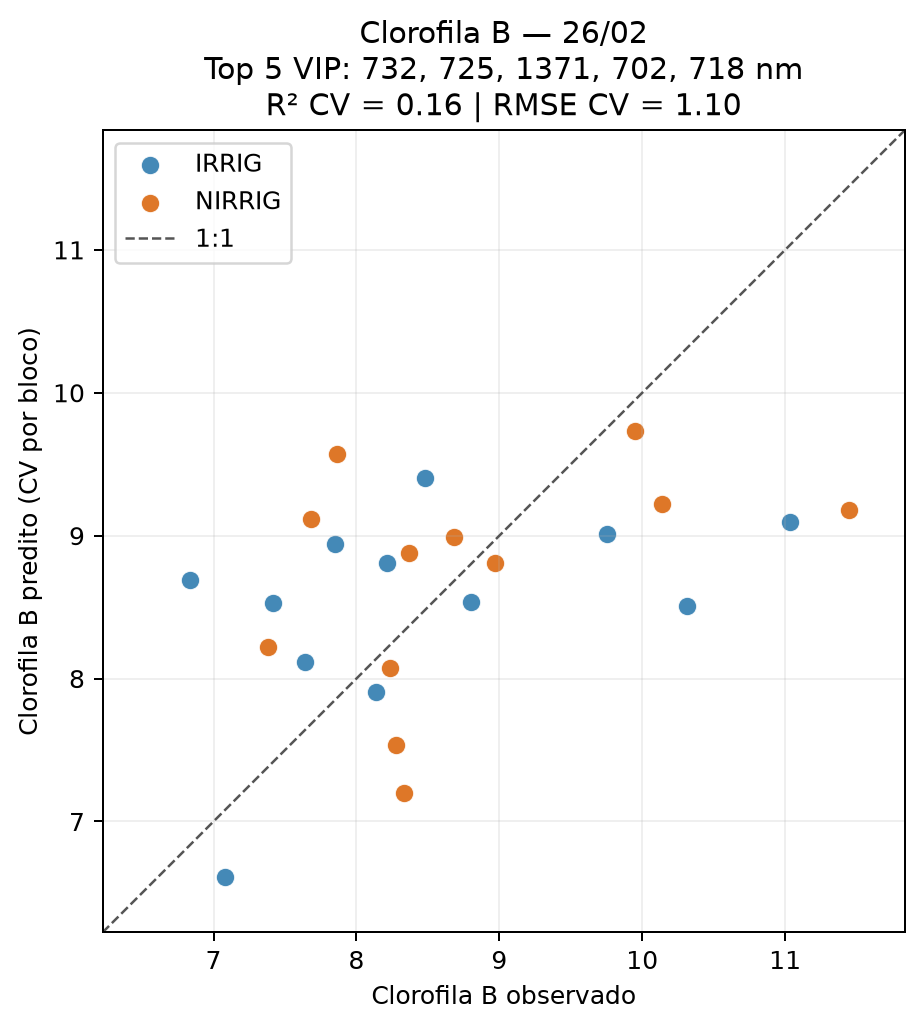

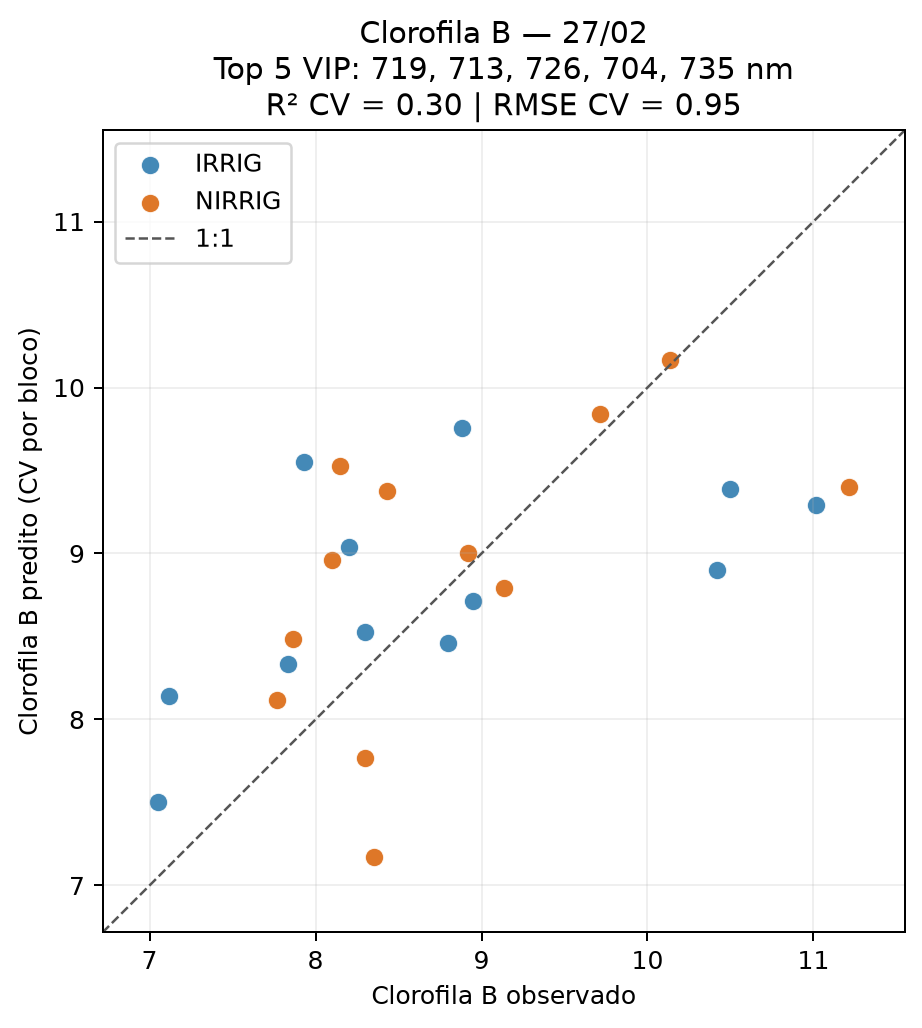

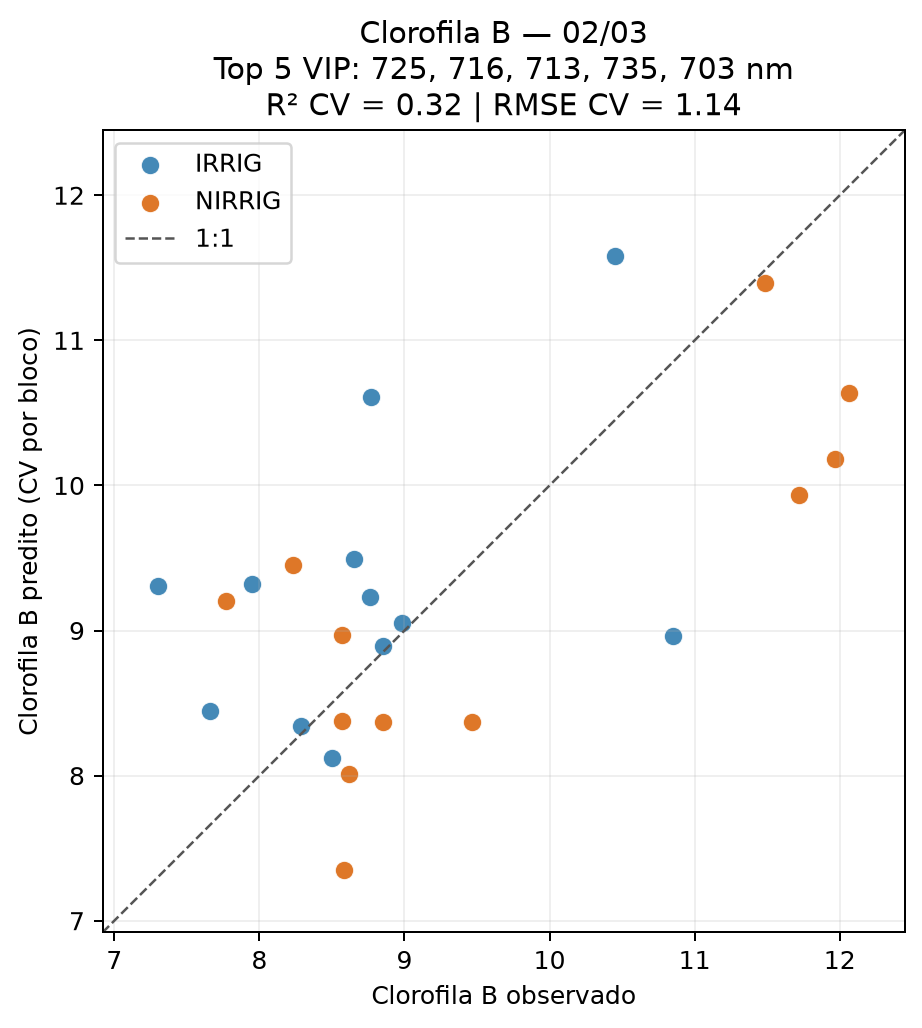

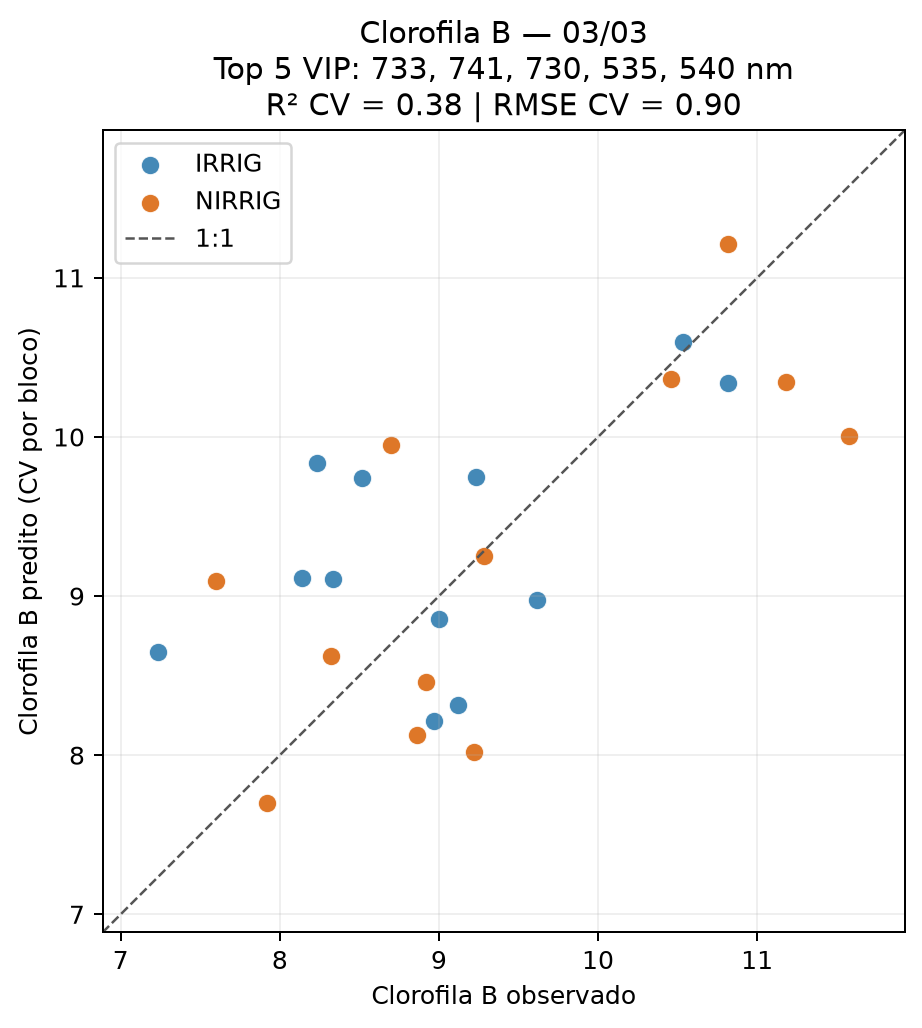

In [ ]:
mostrar_bandas_e_graficos_diarios("Clorofila B")


### 4.7. gs — condutância estomática

Em 23–27/02, 02/03 e 03/03, cada data tem suas próprias cinco bandas VIP e seu próprio PLSR. A tabela abaixo mostra as bandas selecionadas e a predição por validação por bloco.

In [ ]:
executar_plsr_vip_por_dia("gs")
mostrar_resumo_fisiologico("gs")

#### Bandas VIP e gráficos de predição por data

A tabela mostra as cinco bandas de cada dia em ordem de VIP. Os gráficos usam essas bandas no PLSR da própria data e exibem as predições ao deixar um bloco de fora.


Data,VIP 1 (nm),VIP 2 (nm),VIP 3 (nm),VIP 4 (nm),VIP 5 (nm)
23/02,716,726,1942,1931,1926
24/02,1375,1365,1358,1354,1843
25/02,400,410,1370,422,1359
26/02,1936,1922,1946,1370,1952
27/02,1927,1931,1911,724,705
02/03,1940,1951,1959,1932,1967
03/03,2450,400,411,1946,1952


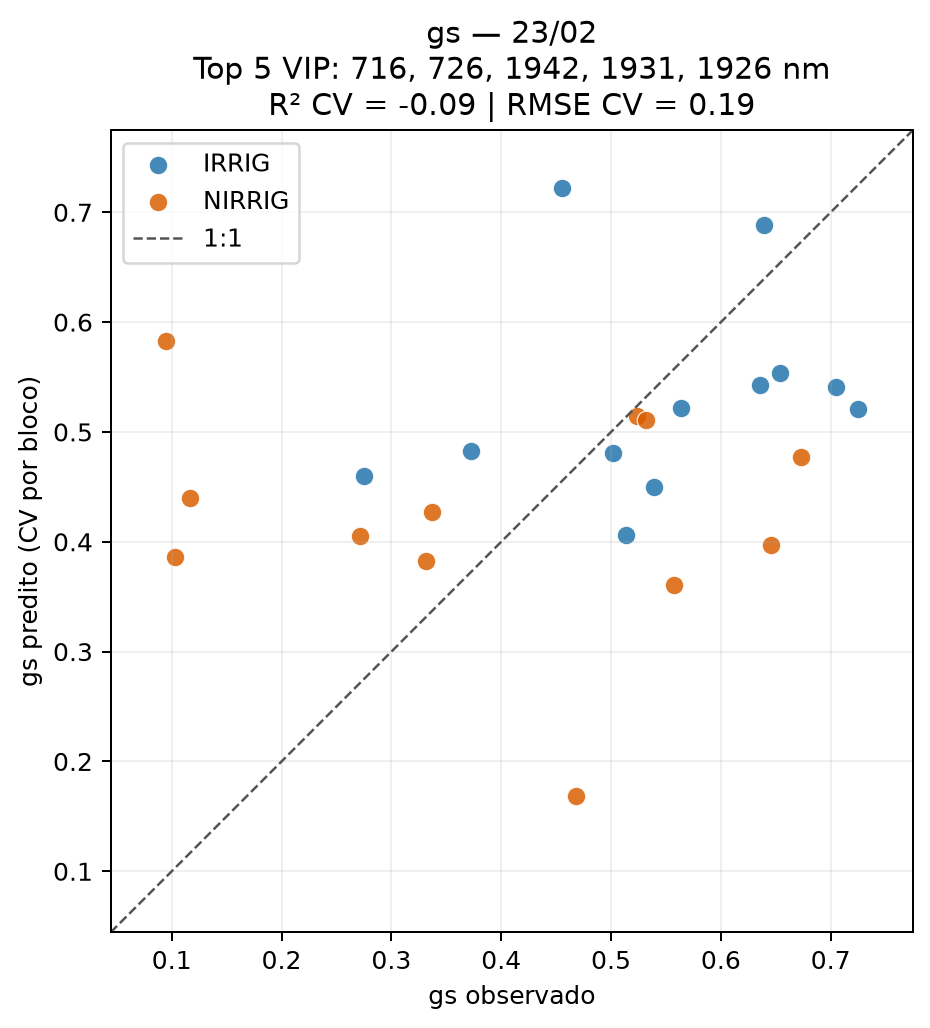

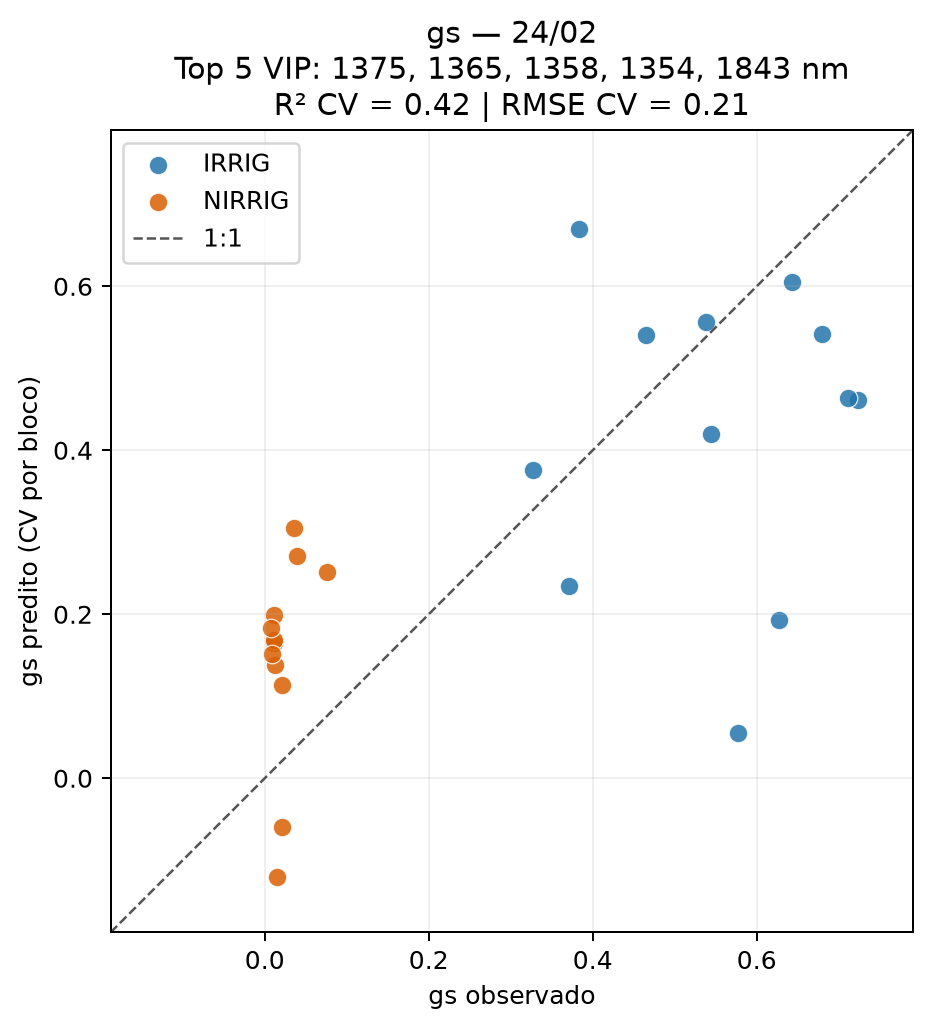

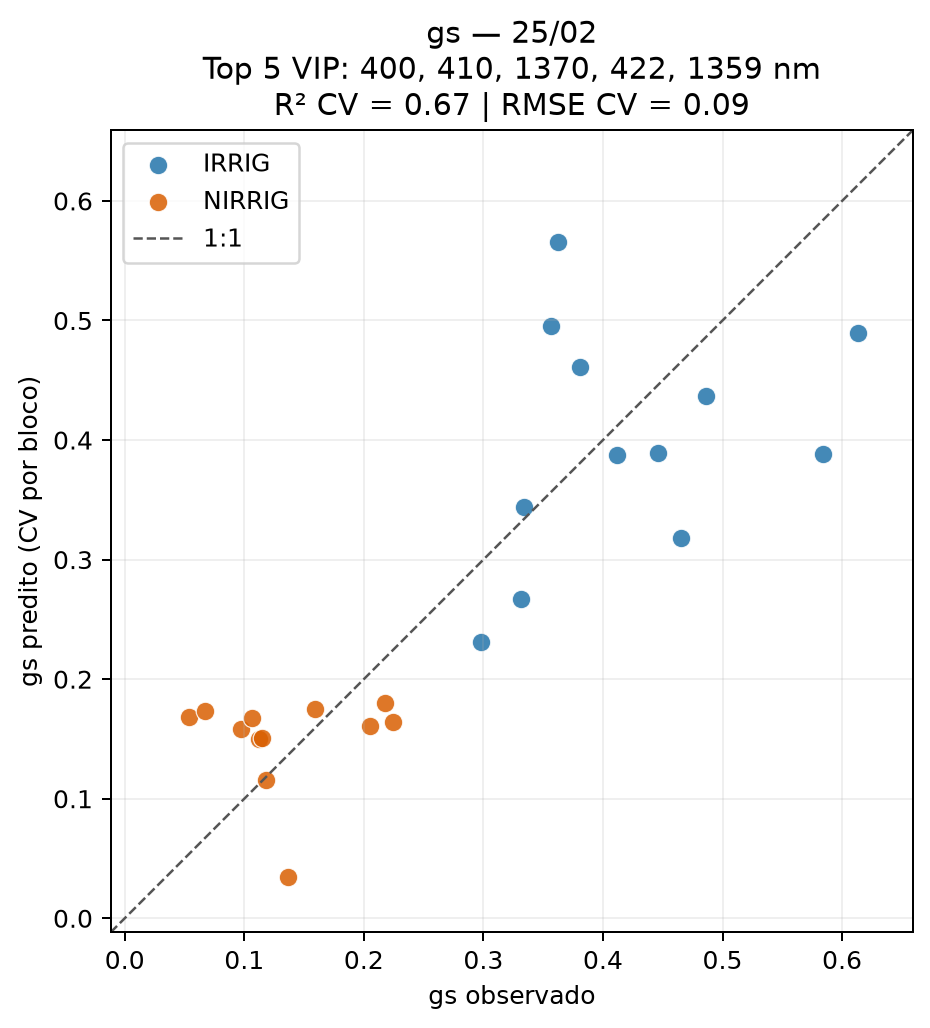

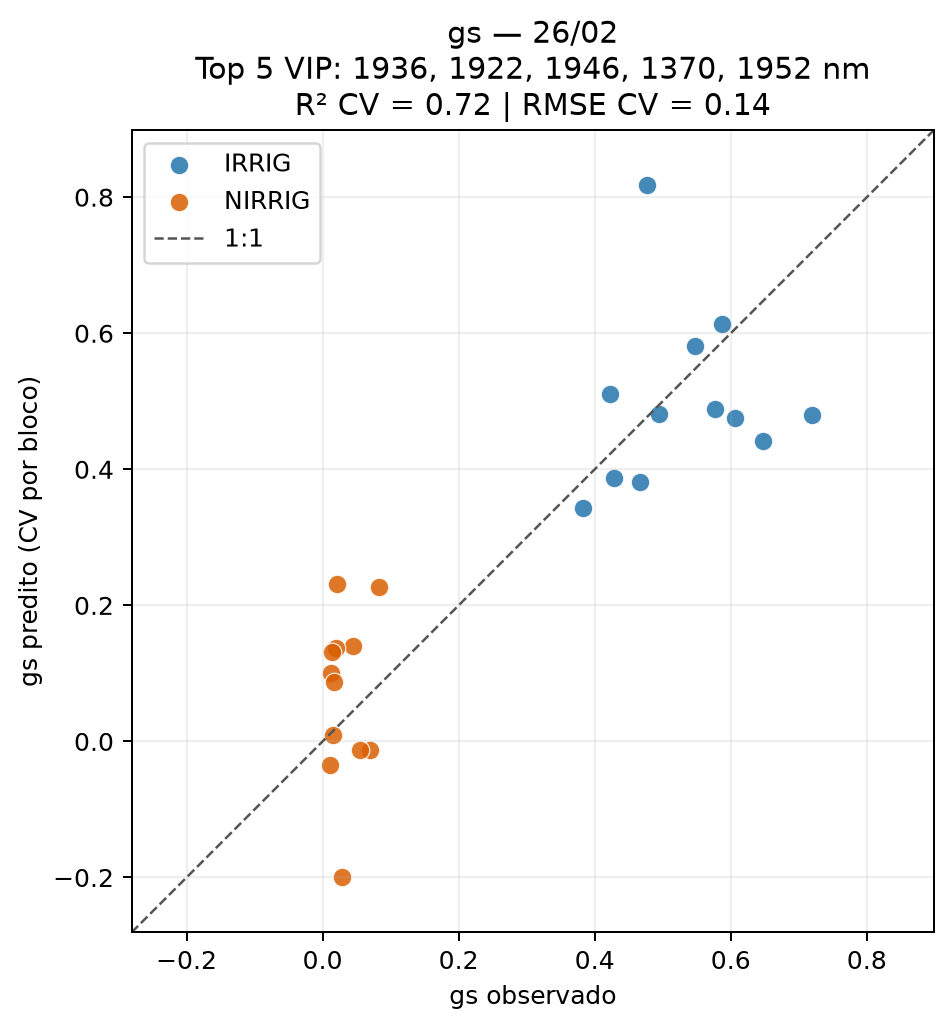

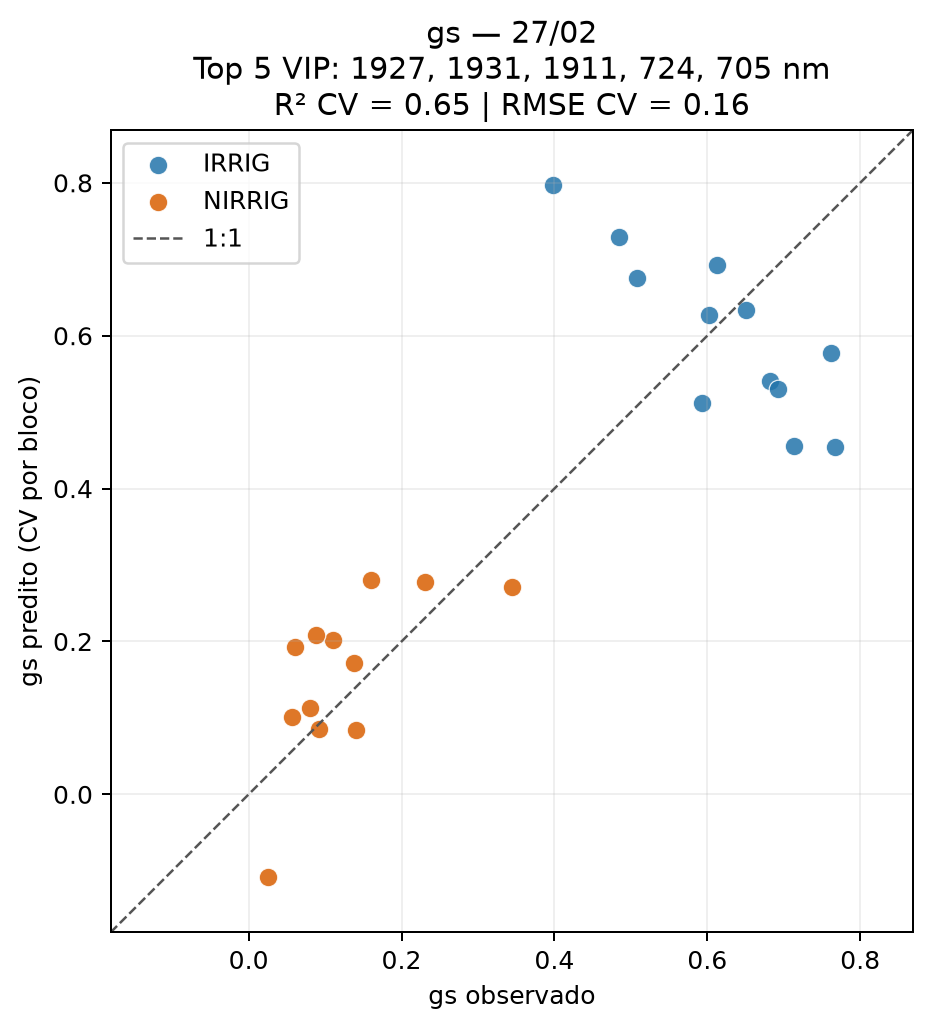

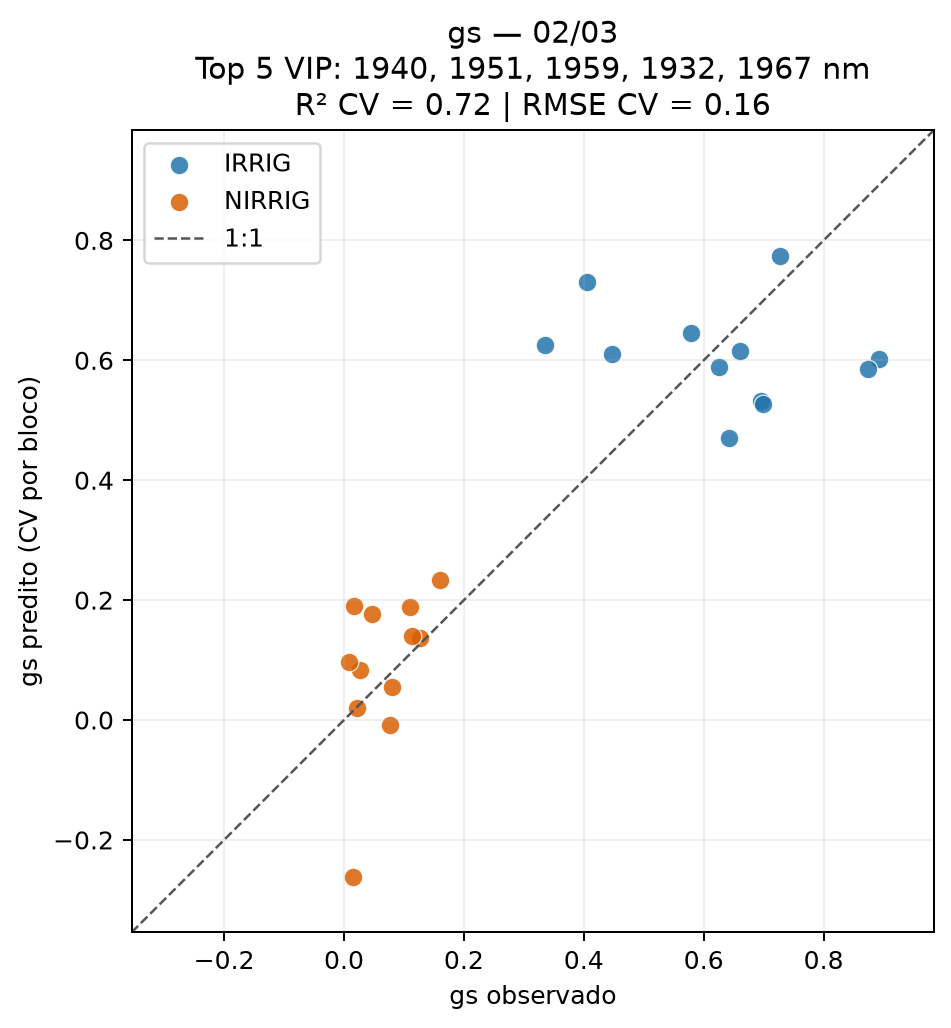

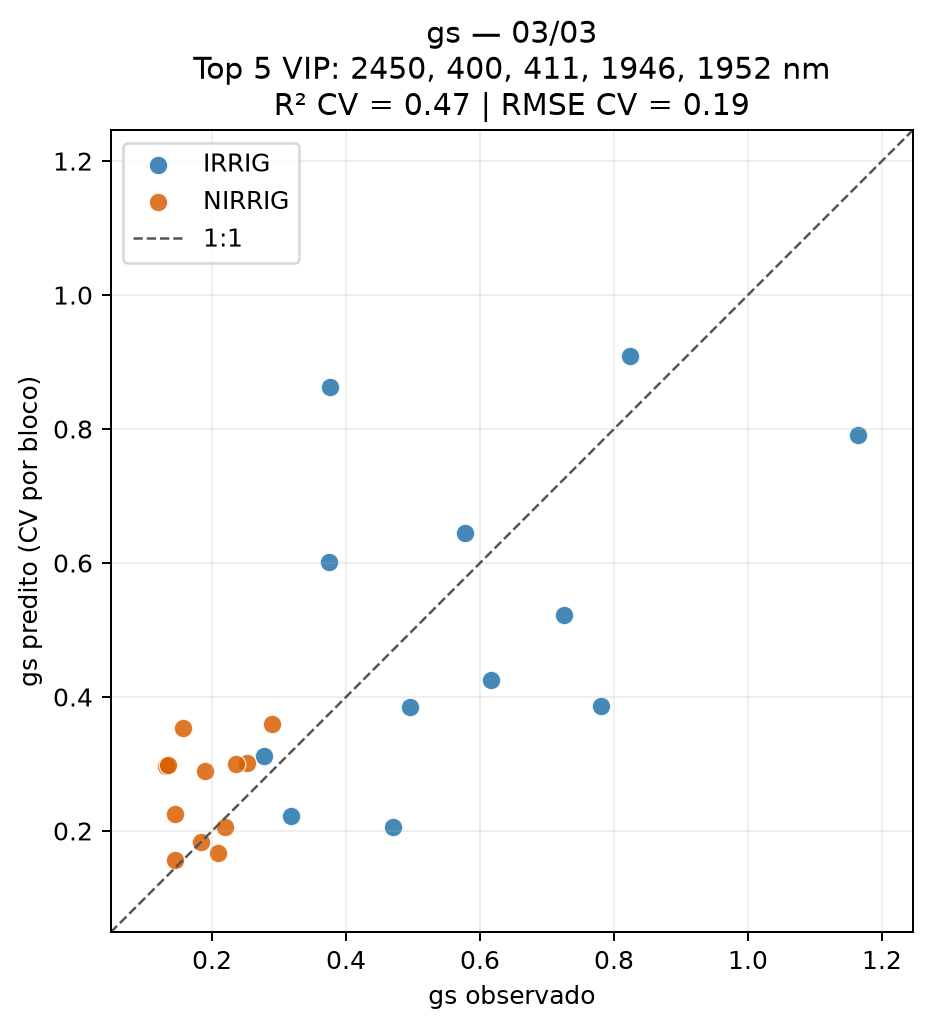

In [ ]:
mostrar_bandas_e_graficos_diarios("gs")


### 4.8. CRA — conteúdo relativo de água

Em 24/02, 02/03 e 03/03, cada data tem suas próprias cinco bandas VIP e seu próprio PLSR. A tabela abaixo mostra as bandas selecionadas e a predição por validação por bloco. A observação sem CRA em 02/03 é excluída.

In [ ]:
executar_plsr_vip_por_dia("CRA")
mostrar_resumo_fisiologico("CRA")

#### Bandas VIP e gráficos de predição por data

A tabela mostra as cinco bandas de cada dia em ordem de VIP. Os gráficos usam essas bandas no PLSR da própria data e exibem as predições ao deixar um bloco de fora.


Data,VIP 1 (nm),VIP 2 (nm),VIP 3 (nm),VIP 4 (nm),VIP 5 (nm)
24/02,1695,1694,1715,1708,1675
02/03,1932,1940,1922,1950,1961
03/03,1661,1671,1655,1898,1901


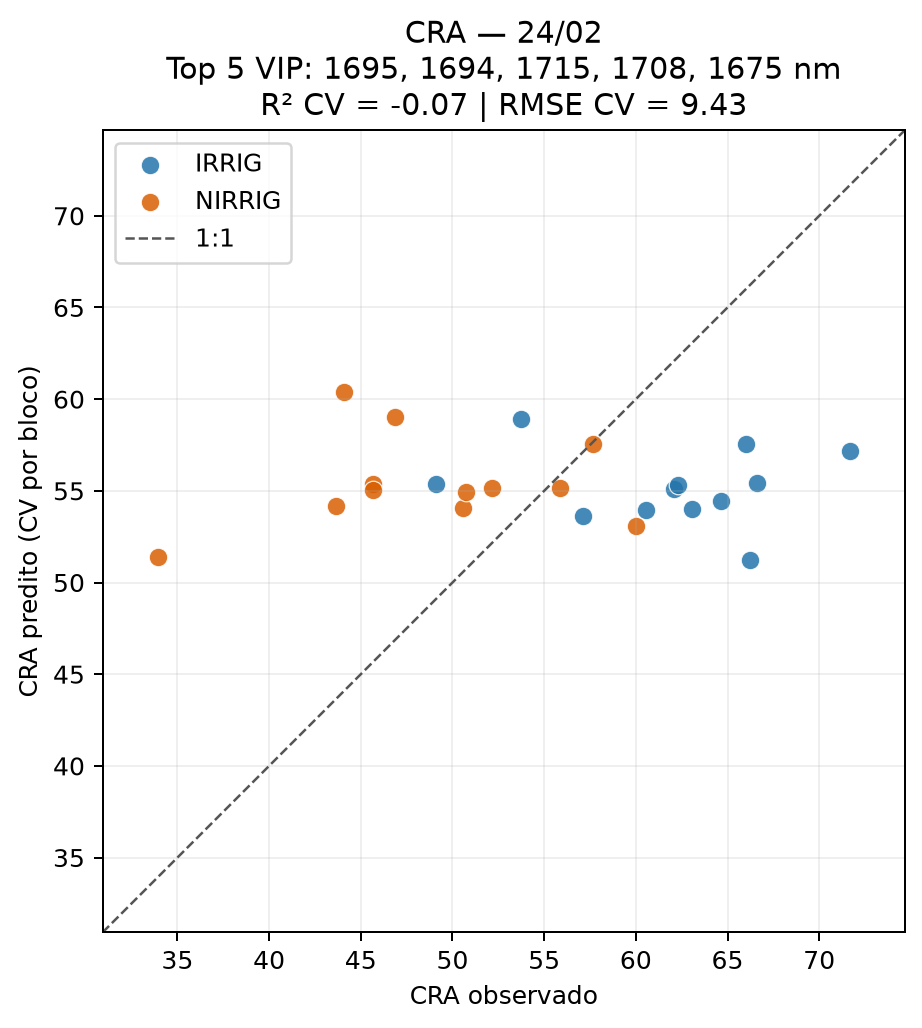

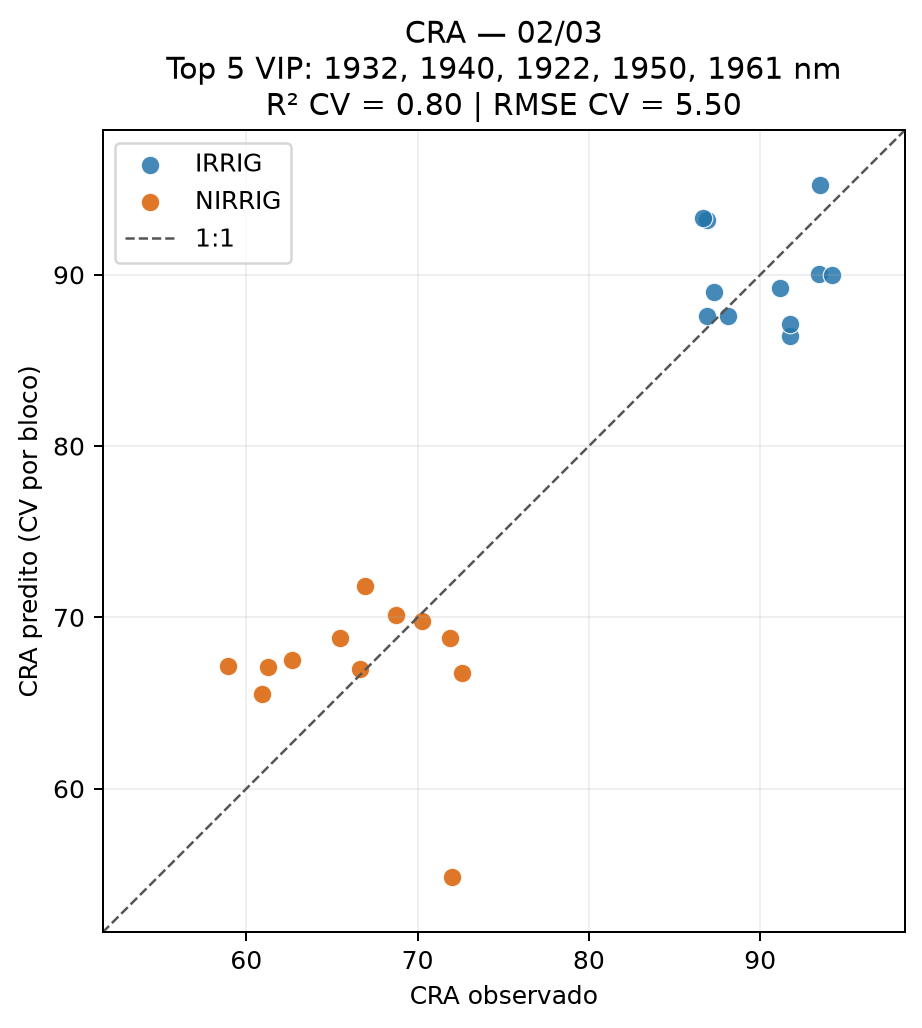

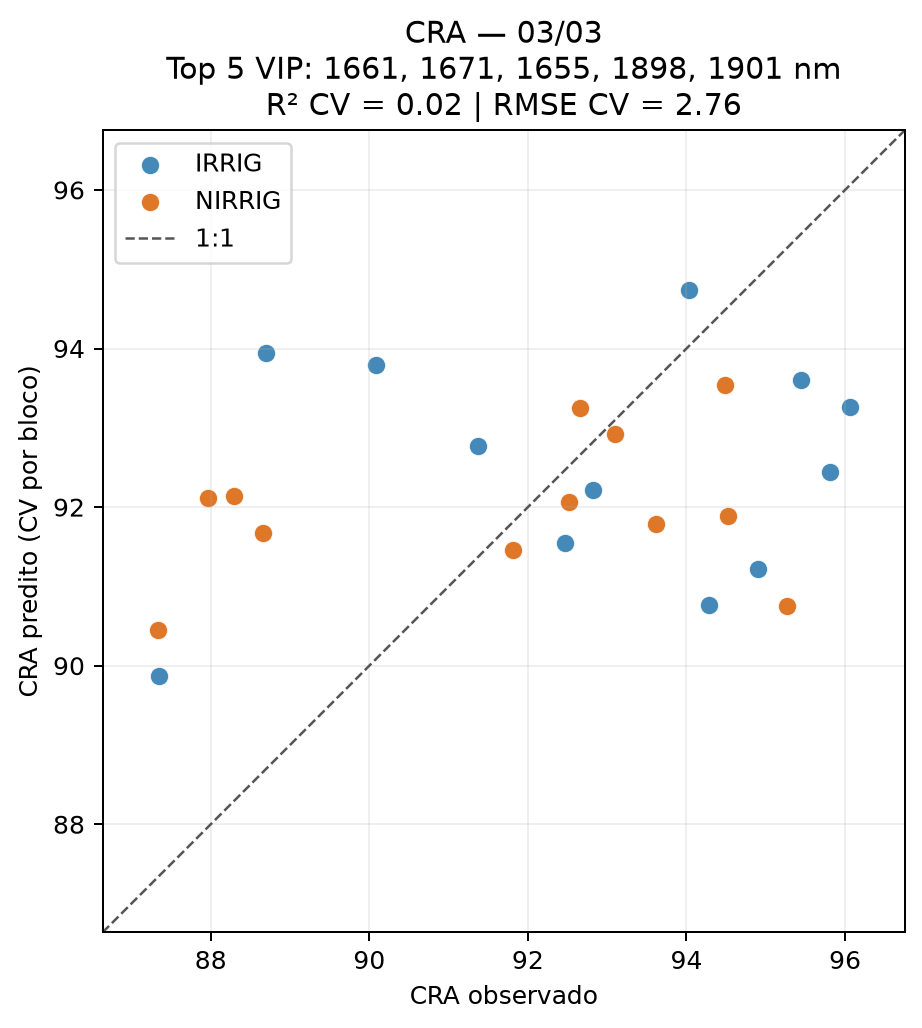

In [ ]:
mostrar_bandas_e_graficos_diarios("CRA")


### 4.9. ETR — taxa de transporte de elétrons

Em 23/02, 02/03 e 03/03, cada data tem suas próprias cinco bandas VIP e seu próprio PLSR. A tabela abaixo mostra as bandas selecionadas e a predição por validação por bloco.

In [ ]:
executar_plsr_vip_por_dia("ETR")
mostrar_resumo_fisiologico("ETR")

#### Bandas VIP e gráficos de predição por data

A tabela mostra as cinco bandas de cada dia em ordem de VIP. Os gráficos usam essas bandas no PLSR da própria data e exibem as predições ao deixar um bloco de fora.


Data,VIP 1 (nm),VIP 2 (nm),VIP 3 (nm),VIP 4 (nm),VIP 5 (nm)
23/02,1904,1908,1917,1896,1927
02/03,1940,1952,1961,1932,1832
03/03,1850,743,737,1831,1651


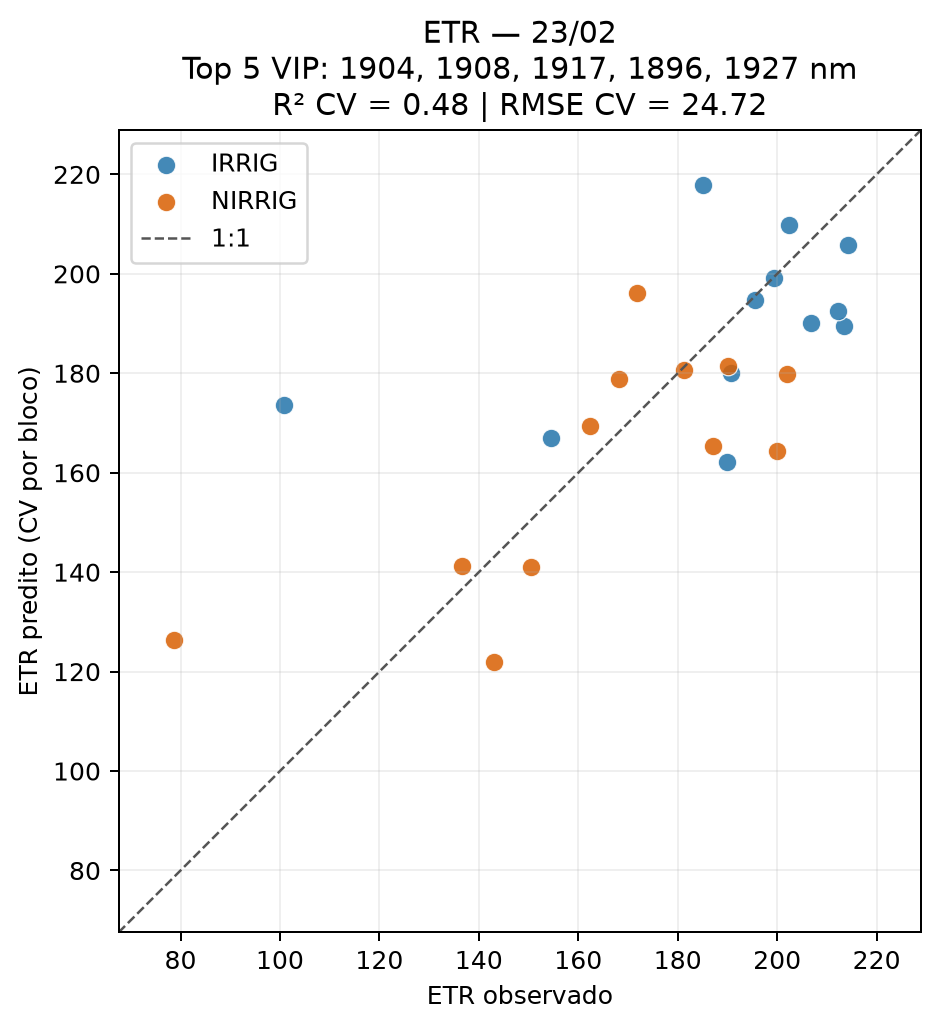

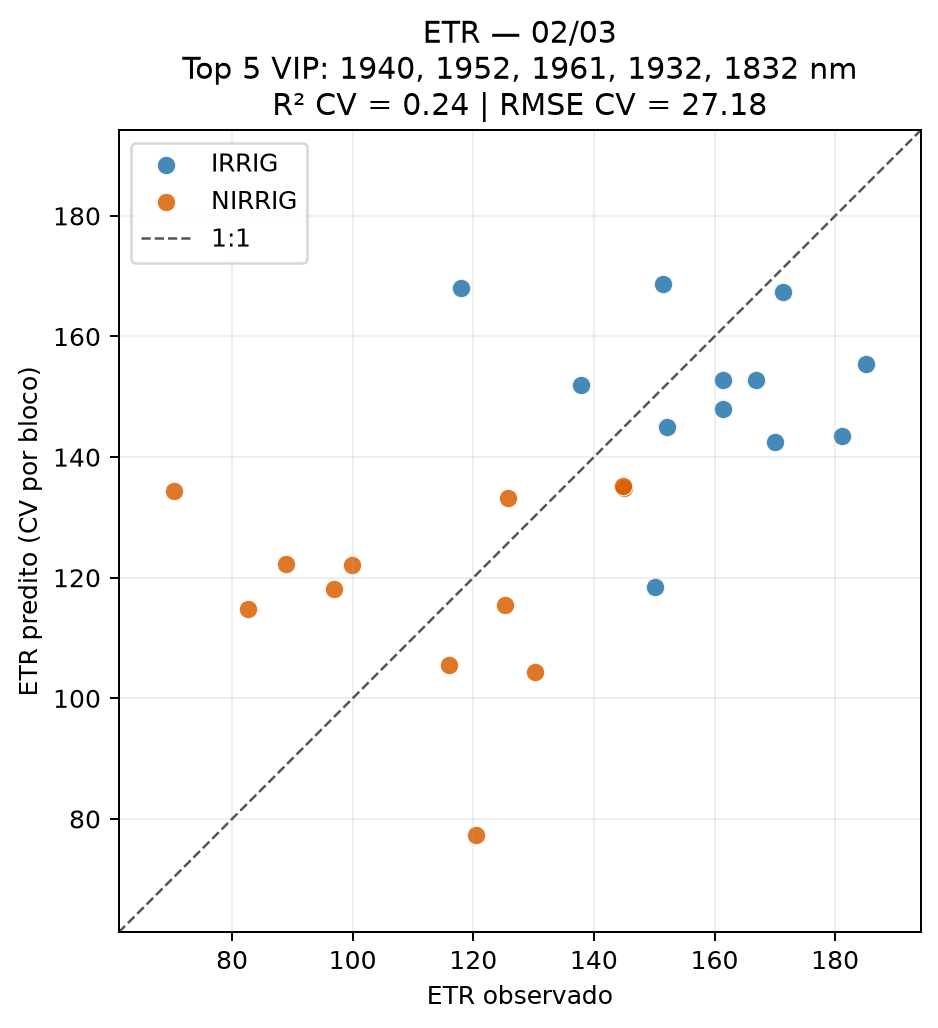

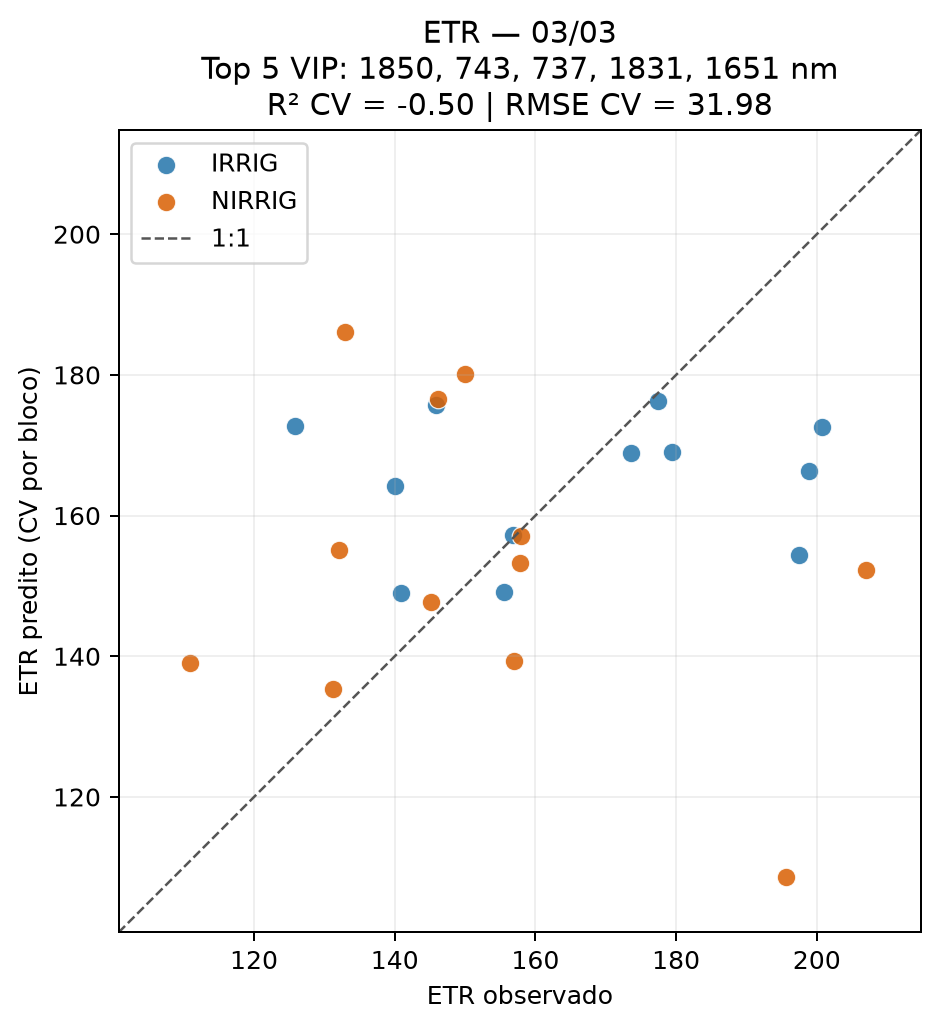

In [ ]:
mostrar_bandas_e_graficos_diarios("ETR")


### 4.10. E

Em 23–27/02, 02/03 e 03/03, cada data tem suas próprias cinco bandas VIP e seu próprio PLSR. A tabela abaixo mostra as bandas selecionadas e a predição por validação por bloco.


In [ ]:
executar_plsr_vip_por_dia("E")
mostrar_resumo_fisiologico("E")


#### Bandas VIP e gráficos de predição por data

A tabela mostra as cinco bandas de cada dia em ordem de VIP. Os gráficos usam essas bandas no PLSR da própria data e exibem as predições ao deixar um bloco de fora.


Data,VIP 1 (nm),VIP 2 (nm),VIP 3 (nm),VIP 4 (nm),VIP 5 (nm)
23/02,1937,1949,1957,1927,1924
24/02,1375,1365,1355,1349,1942
25/02,400,410,422,430,1367
26/02,1922,1936,1945,1952,1908
27/02,724,705,734,1927,1931
02/03,1938,1932,1952,1922,1961
03/03,2450,1940,1946,1952,1928


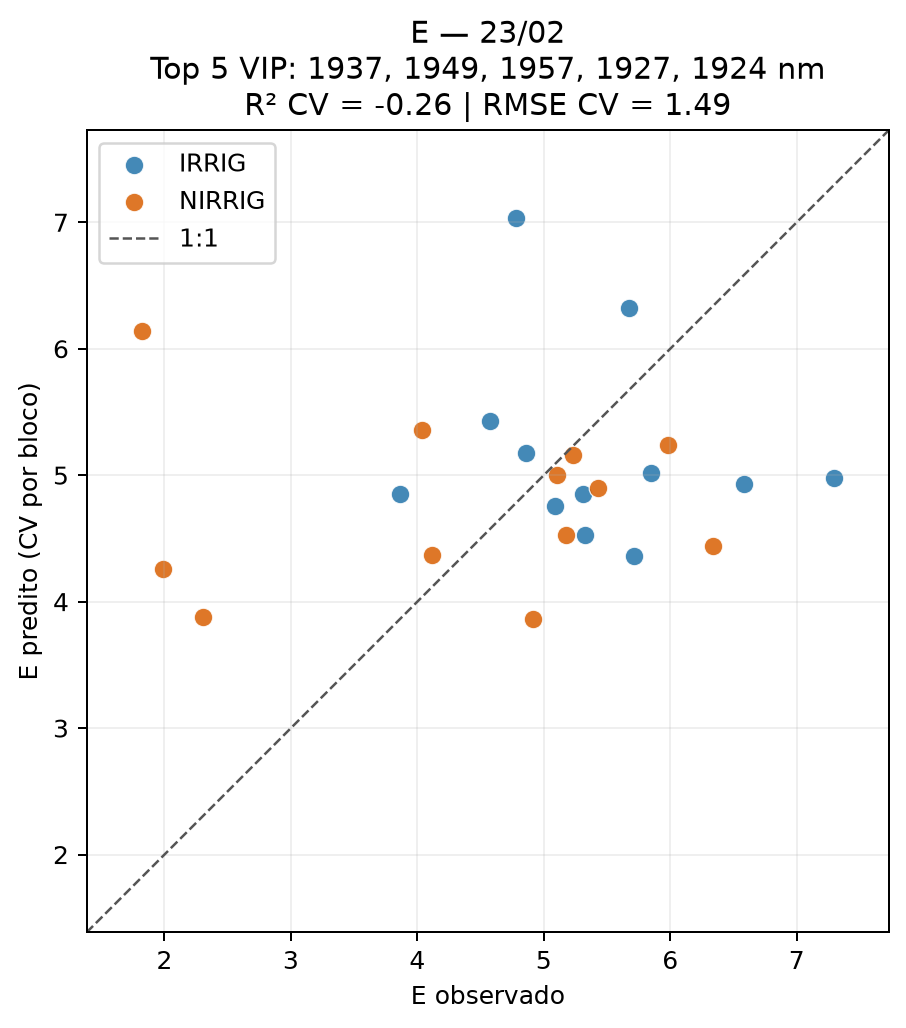

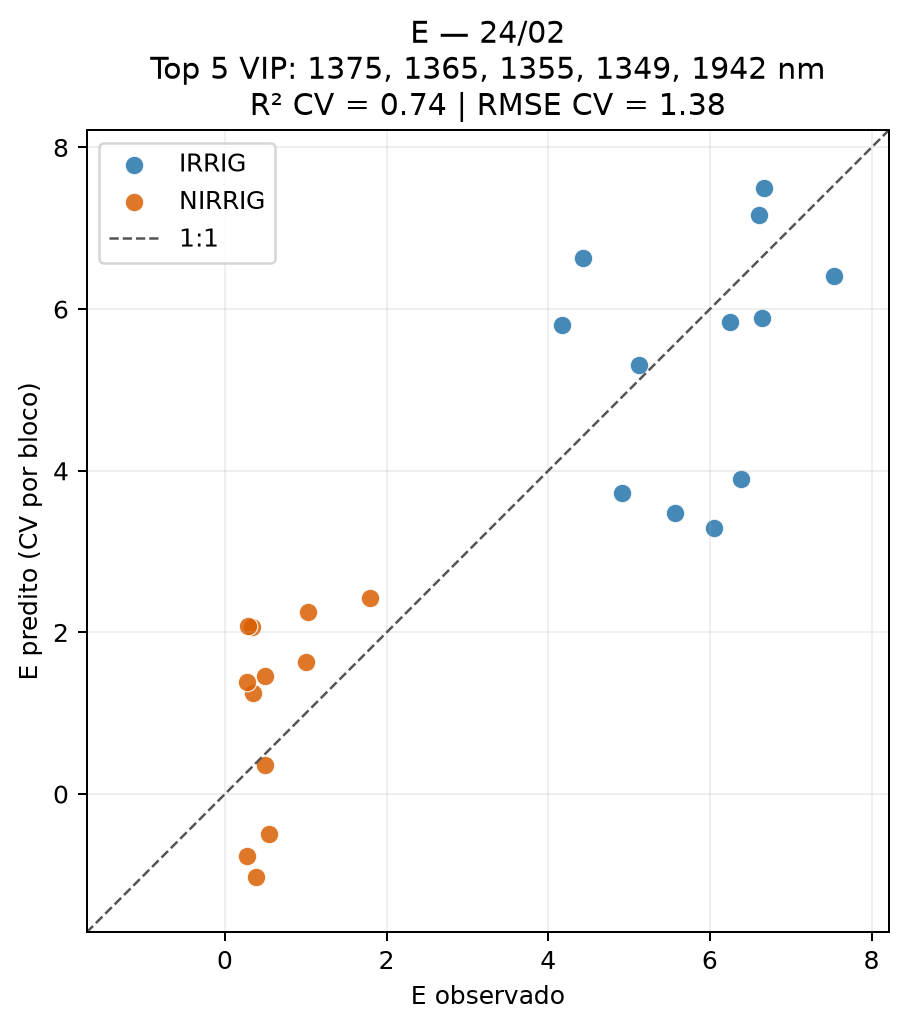

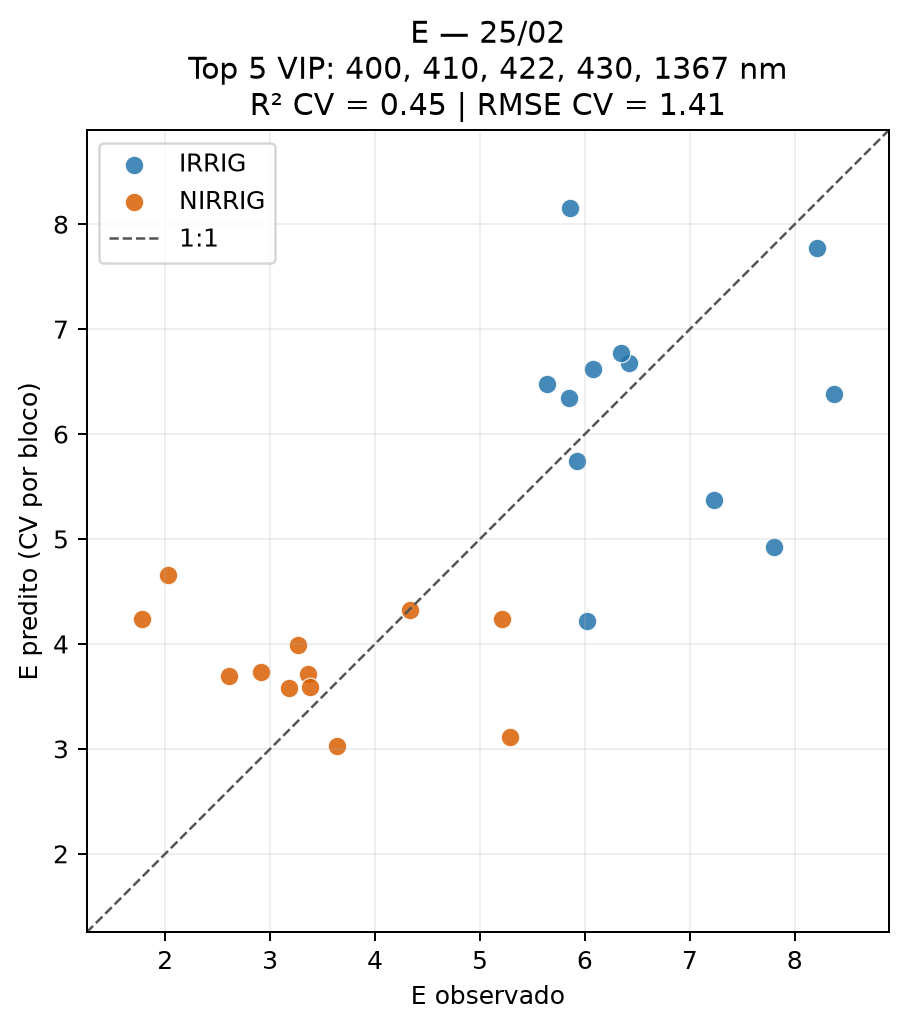

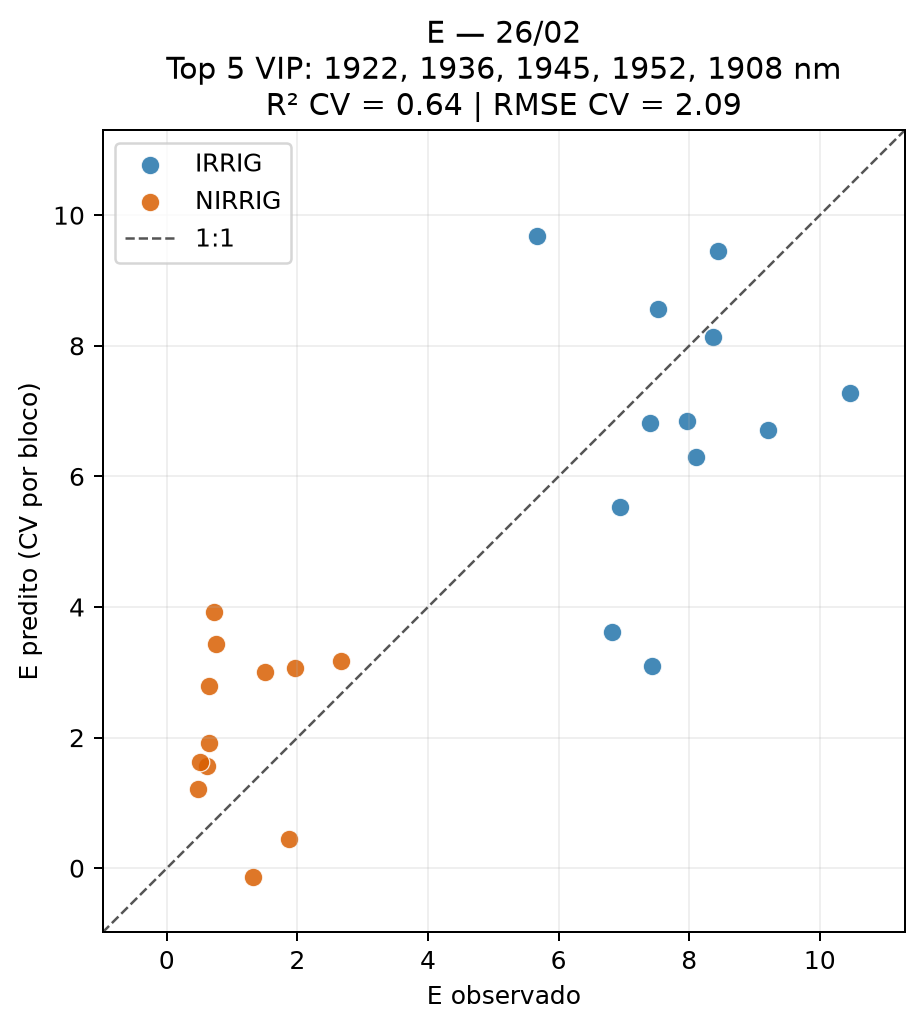

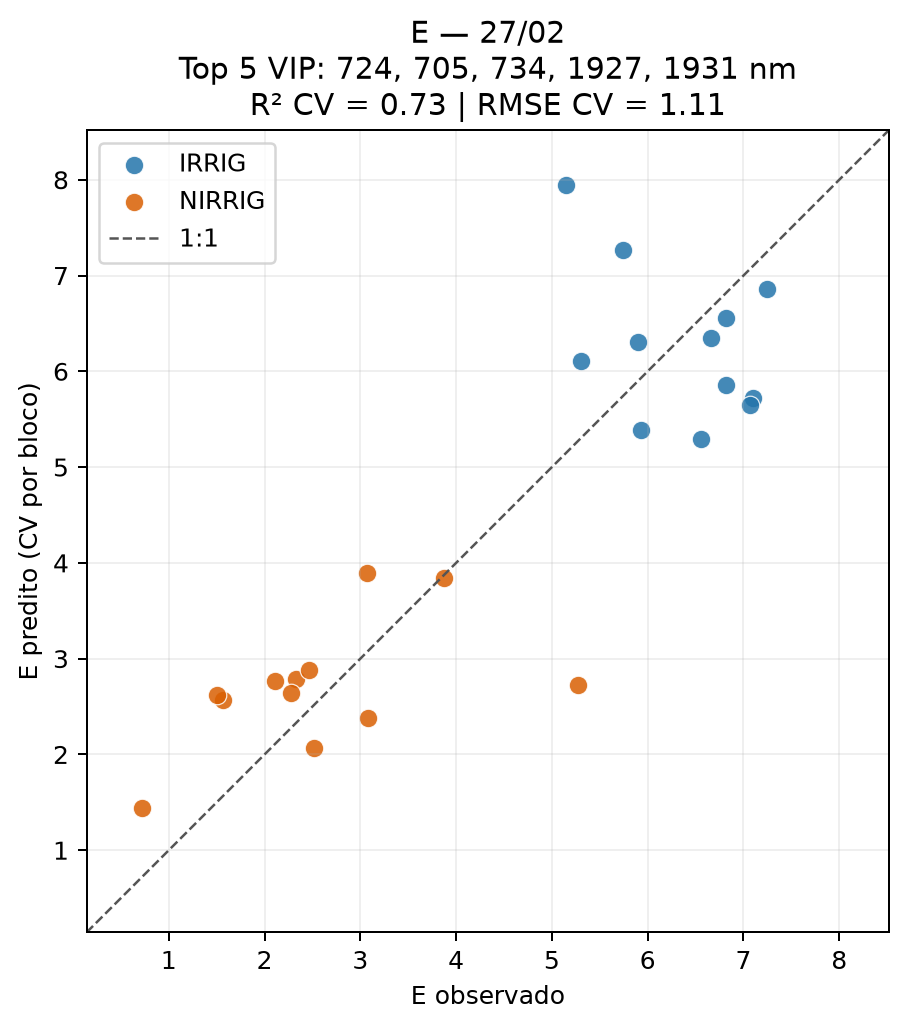

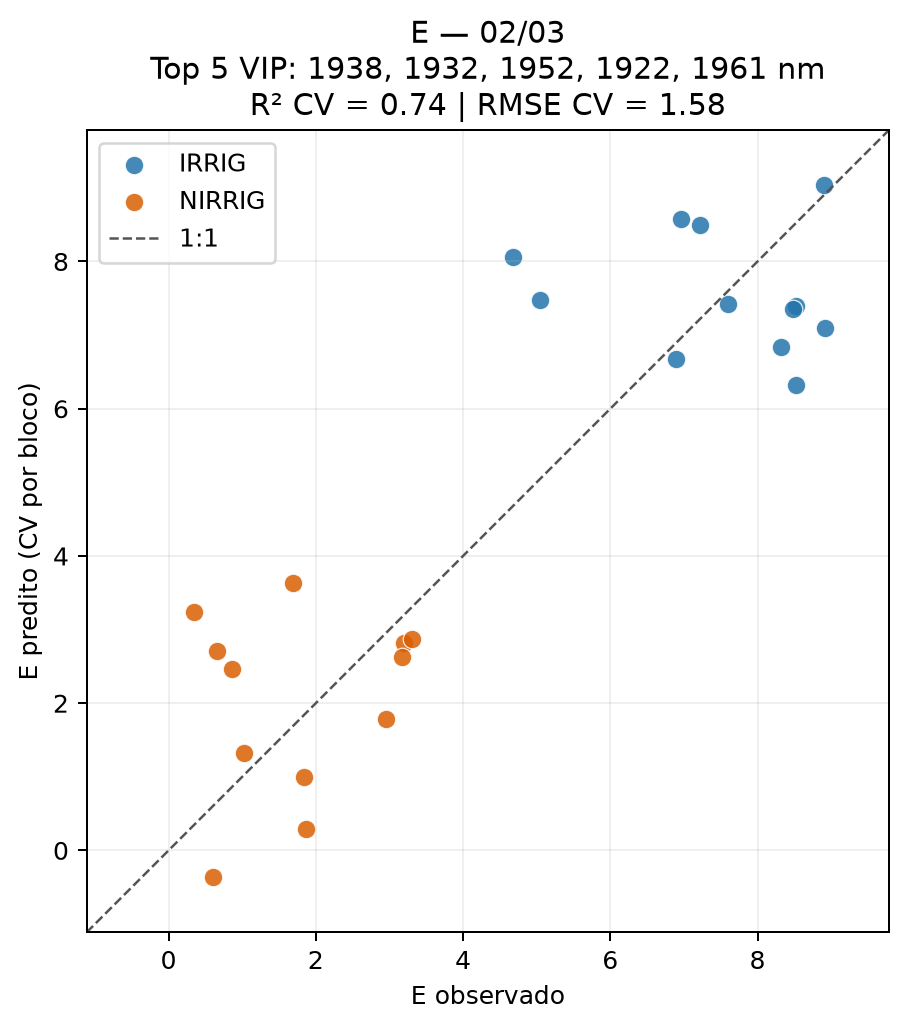

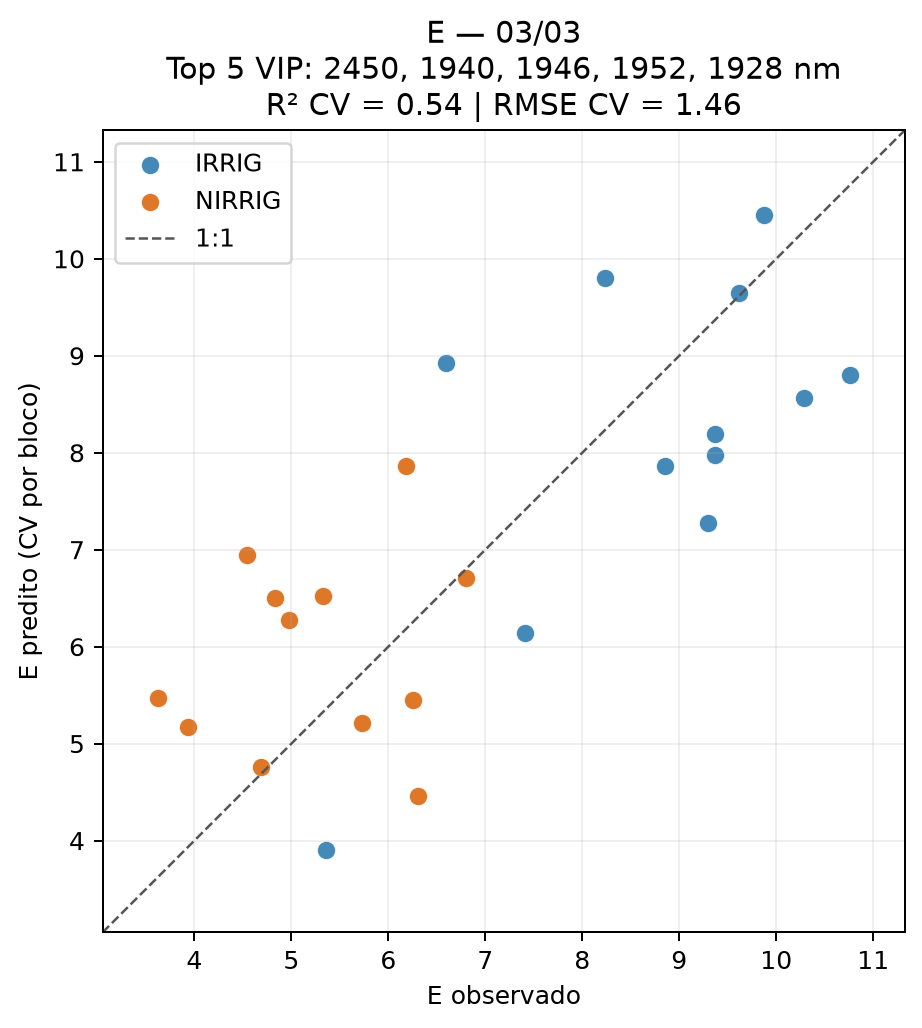

In [ ]:
mostrar_bandas_e_graficos_diarios("E")


### 4.11. Resultados diários e bandas VIP

O resumo reúne R² e RMSE de ajuste e de validação por bloco. A tabela de bandas registra as cinco escolhidas por VIP em cada data, e o arquivo de predições guarda valores observados, preditos e resíduos por parcela.

In [ ]:
resumo_fisiologia_diaria = pd.DataFrame(resumos_fisiologia)
predicoes_fisiologia_diaria = pd.concat(predicoes_fisiologia, ignore_index=True)
resumo_fisiologia_diaria.to_csv(
    PASTA_FISIOLOGIA / "resumo_predicao_diaria.csv", sep=";", index=False
)
predicoes_fisiologia_diaria.to_csv(
    PASTA_FISIOLOGIA / "predicoes_cv_bloco.csv", sep=";", index=False
)
display(resumo_fisiologia_diaria[[
    "parametro", "data", "n", "bandas_modelo", "componentes",
    "r2_cv_bloco", "rmse_cv_bloco", "status",
]].round(3))

fig, eixos = plt.subplots(2, 4, figsize=(20, 8), constrained_layout=True)
for eixo, alvo in zip(eixos.flat, ALVOS_FISIOLOGICOS):
    dados = resumo_fisiologia_diaria.loc[
        resumo_fisiologia_diaria["parametro"].eq(alvo)
    ]
    eixo.plot(dados["data"], dados["r2_cv_bloco"], marker="o", color="#2a78d6")
    eixo.axhline(0, color="#555555", linewidth=0.8)
    eixo.set_title(alvo, fontweight="bold")
    eixo.set_ylabel("R² CV por bloco (diagnóstico)")
    eixo.tick_params(axis="x", rotation=45)
    eixo.grid(alpha=0.25)
for eixo in list(eixos.flat)[len(ALVOS_FISIOLOGICOS):]:
    eixo.set_visible(False)
fig.savefig(PASTA_FISIOLOGIA / "r2_cv_por_parametro_e_dia.png", dpi=170, bbox_inches="tight")
display(fig)
plt.close(fig)

bandas_vip_por_dia = pd.concat(bandas_vip_fisiologia, ignore_index=True)
bandas_vip_por_dia.to_csv(
    PASTA_FISIOLOGIA / "top5_vip_por_dia.csv", sep=";", index=False
)
display(bandas_vip_por_dia)

### 4.12. Predições e bandas VIP ao longo dos dias

Cada painel compara valores observados e preditos de uma data, com cores para as condições hídricas. Outro gráfico reúne, para cada parâmetro, todas as datas e as cinco bandas selecionadas em cada uma. As figuras são salvas em `script_final/outputs/fisiologia_vip_por_dia/`.

In [ ]:
CORES_CONDICAO_FISIOLOGIA = {"IRRIG": "#2374ab", "NIRRIG": "#d95f02"}

def grafico_predicao_fisiologica(alvo: str) -> None:
    _, datas = ALVOS_FISIOLOGICOS[alvo]
    n_colunas = min(4, len(datas))
    n_linhas = int(np.ceil(len(datas) / n_colunas))
    fig, eixos = plt.subplots(
        n_linhas, n_colunas, figsize=(4.3 * n_colunas, 4 * n_linhas),
        squeeze=False, constrained_layout=True,
    )
    for eixo, data in zip(eixos.flat, datas):
        metrica = resumo_fisiologia_diaria.loc[
            resumo_fisiologia_diaria["parametro"].eq(alvo)
            & resumo_fisiologia_diaria["data"].eq(data)
        ].iloc[0]
        dia = predicoes_fisiologia_diaria.loc[
            predicoes_fisiologia_diaria["parametro"].eq(alvo)
            & predicoes_fisiologia_diaria["data"].eq(data)
        ]
        if dia.empty:
            eixo.text(0.5, 0.5, metrica["status"], ha="center", va="center",
                      transform=eixo.transAxes, color="#777777")
            eixo.set_title(data)
            eixo.set_xticks([])
            eixo.set_yticks([])
            continue
        valores = np.r_[dia["observado"].to_numpy(),
                        dia["predito_cv_bloco"].to_numpy()]
        amplitude = np.ptp(valores)
        margem = max(0.05 * amplitude, 0.01)
        minimo, maximo = np.min(valores) - margem, np.max(valores) + margem
        for condicao, cor in CORES_CONDICAO_FISIOLOGIA.items():
            parcela = dia.loc[dia["condicao"].eq(condicao)]
            if not parcela.empty:
                eixo.scatter(parcela["observado"], parcela["predito_cv_bloco"],
                             label=condicao, color=cor, alpha=0.78, s=32)
        eixo.plot([minimo, maximo], [minimo, maximo], "--",
                  color="#555555", linewidth=1)
        eixo.set_xlim(minimo, maximo)
        eixo.set_ylim(minimo, maximo)
        eixo.set_aspect("equal", adjustable="box")
        eixo.set_title(f"{data} | R²={metrica['r2_cv_bloco']:.2f}; "
                       f"RMSE={metrica['rmse_cv_bloco']:.2f}")
        eixo.set_xlabel("Observado")
        eixo.set_ylabel("Predito (CV por bloco)")
        eixo.grid(alpha=0.2)
    for eixo in list(eixos.flat)[len(datas):]:
        eixo.set_visible(False)
    handles, labels = [], []
    for eixo in eixos.flat:
        handles, labels = eixo.get_legend_handles_labels()
        if handles:
            break
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=2,
                   bbox_to_anchor=(0.5, 0.0))
    fig.suptitle(f"{alvo}: observado × predito por dia", fontweight="bold")
    nome = alvo.lower().replace(" ", "_")
    fig.savefig(PASTA_FISIOLOGIA / f"predicao_{nome}_por_dia.png",
                dpi=170, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def grafico_bandas_vip_por_dia(alvo: str) -> None:
    _, datas = ALVOS_FISIOLOGICOS[alvo]
    dados = bandas_vip_por_dia.loc[
        bandas_vip_por_dia["parametro"].eq(alvo)
    ].copy()
    posicoes = {data: i for i, data in enumerate(datas)}
    # Uma linha para cada banda evita sobrepor rótulos de comprimentos próximos.
    dados["linha"] = dados["data"].map(posicoes) * 6 + dados["posicao_vip"]
    figura, eixo = plt.subplots(
        figsize=(13, max(5, 1.65 * len(datas) + 1.5)),
        constrained_layout=True,
    )
    pontos = eixo.scatter(
        dados["banda_nm"], dados["linha"],
        c=dados["vip_selecao"], cmap="viridis", s=105,
        edgecolors="#333333", linewidths=0.5, zorder=3,
    )
    for linha in dados.itertuples():
        eixo.annotate(
            f"{int(linha.banda_nm)} nm",
            (linha.banda_nm, linha.linha),
            xytext=(8, 0), textcoords="offset points",
            va="center", fontsize=8,
        )
    for indice in range(1, len(datas)):
        eixo.axhline(indice * 6 + 0.5, color="#dddddd", linewidth=0.8)
    eixo.set_yticks([i * 6 + 3 for i in range(len(datas))], labels=datas)
    eixo.set_ylim(len(datas) * 6 + 0.5, 0)
    eixo.set_xlim(380, 2470)
    eixo.set_xlabel("Comprimento de onda (nm)")
    eixo.set_ylabel("Data (bandas em ordem de VIP)")
    eixo.set_title(f"{alvo}: Top 5 bandas VIP por data")
    eixo.grid(axis="x", alpha=0.25)
    figura.colorbar(pontos, ax=eixo, label="VIP no PLSR inicial da data")
    nome = alvo.lower().replace(" ", "_")
    figura.savefig(PASTA_FISIOLOGIA / f"top5_vip_{nome}_por_dia.png",
                   dpi=180, bbox_inches="tight")
    display(figura)
    plt.close(figura)


for alvo in ALVOS_FISIOLOGICOS:
    grafico_predicao_fisiologica(alvo)
    grafico_bandas_vip_por_dia(alvo)